In [26]:
# command to reload libraries
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
import warnings

from desReg.des.DESRegression import DESRegression
from desReg.utils import measures as em
from run_experiments import run_experiment_with_timeout, get_agg_results, get_df_results
from run_experiments import partitions_dict

import numpy as np
import pandas as pd
import datetime as dt
import seaborn as sns
from scipy.spatial import distance
from sklearn.svm import SVR
from sklearn.linear_model import Lasso
from sklearn import linear_model
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error
from matplotlib import pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='The default value of `dual` will change')

pd.set_option('display.max_columns', None)

In [28]:
train_df_dict= {}
datasets = {}
for partition_alias, partition_name in partitions_dict.items():
    n_fold = 5
    train_df = pd.DataFrame()
    test_df = pd.DataFrame()
    for p in range(1,n_fold+1):
        name_train = partition_name+str(p)+'tra.dat'
        name_test = partition_name+str(p)+'tst.dat'

        data_train = pd.read_csv(name_train,header = None)
        columns = [f"V{i}" for i in range(data_train.shape[1] - 1)]
        columns.append("y")
        data_train.columns = columns
        X_train = data_train.iloc[:,:-1].to_numpy()
        y_train = np.ravel(data_train.iloc[:, -1:])

        data_test = pd.read_csv(name_test, header=None)
        data_test.columns = columns
        X_test = data_test.iloc[:,:-1].to_numpy()
        y_test = np.ravel(data_test.iloc[:, -1:])

        train_df = pd.concat([train_df, data_train], ignore_index=True)
        test_df = pd.concat([test_df, data_test], ignore_index=True)

    datasets[partition_alias] = dict(
        train_df = train_df,
        test_df = test_df
    )

## Utils

In [29]:
def process_prediction_results(model_results, dataset_name):
    predictions_results = pd.DataFrame()
    for part in model_results:
        for model in model_results[part].keys():
            new_df = pd.DataFrame(model_results[part][model])\
                [['y_pred', 'y_true']]\
                .assign(dataset=dataset_name)\
                .assign(model_name=model)\
                .assign(partition=part)
            predictions_results = pd.concat([
                predictions_results, 
                new_df
            ], ignore_index=True)
    return predictions_results

def process_predictions(predictions_df, meta_features_dict):
    list_df = list()
    for model in predictions_df['model_name'].unique():
        model_df = predictions_df.query("model_name == @model").reset_index(drop=True)
        tmp_df = pd.concat([
            model_df, 
            meta_features_dict['instance_hardness'][['instance_hardness']],
            meta_features_dict['hardness_measures'],
        ], axis=1)
        list_df.append(tmp_df)
    concatenated_df = pd.concat(list_df, ignore_index=True)
    concatenated_df['error_abs'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred'])
    concatenated_df['error_rel'] = \
        np.abs(concatenated_df['y_true'] - concatenated_df['y_pred']) / concatenated_df['y_true']
    concatenated_df['error_rel_sq'] = \
        (concatenated_df['y_true'] - concatenated_df['y_pred']) ** 2 / concatenated_df['y_true'] ** 2
    concatenated_df['instance_hardness_bin'] = pd.cut(
        concatenated_df['instance_hardness'], 
        bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
        include_lowest=True
    )
    return concatenated_df

def calculate_avg_residual_per_ih(concatenated_df):
    avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\
        .agg(
            avg_error_rel=("error_rel", "mean"),
            std_error_rel=("error_rel", "std")
        )\
        .reset_index()\
        .dropna()\
        .assign(instance_hardness_str_bin=lambda x: x['instance_hardness_bin'].astype(str))
    return avg_residual_per_ih

def plot_avg_residual_per_ih(avg_residual_per_ih):
    sns.lineplot(
        data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
        x='instance_hardness_str_bin',
        y='avg_error_rel',
        hue='model_name'
    )


## Calculate instance hardness


In [30]:
from desReg.utils import instance_hardness as ih

all_meta_features_dict = {}
for name, data in datasets.items():
    # if name in ["yacht"]:
    all_meta_features_dict[name] = dict()
    X_train = data['train_df'].drop(columns=['y'])
    y_train = data['train_df'][['y']]
    instance_hardness_df = ih.get_instance_hardness(X_train, y_train)
    all_hardness_measures = ih.get_hardness_measures(X_train, y_train)
    all_meta_features_dict[name]['instance_hardness'] = instance_hardness_df
    all_meta_features_dict[name]['hardness_measures'] = all_hardness_measures

In [31]:
all_meta_features_test_dict = {}
for name, data in datasets.items():
    # if name in ["yacht"]:
    all_meta_features_test_dict[name] = dict()
    X_test = data['test_df'].drop(columns=['y'])
    y_test = data['test_df'][['y']]
    instance_hardness_df = ih.get_instance_hardness(X_test, y_test)
    all_hardness_measures = ih.get_hardness_measures(X_test, y_test)
    all_meta_features_test_dict[name]['instance_hardness'] = instance_hardness_df
    all_meta_features_test_dict[name]['hardness_measures'] = all_hardness_measures

In [32]:
consolidated_meta_features_train = dict()
for name in all_meta_features_dict.keys():
    consolidated_meta_features_train[name] = ih.consolidate_data(
        all_meta_features_dict[name]['instance_hardness'], 
        all_meta_features_dict[name]['hardness_measures']
    )

consolidated_meta_features_test = dict()
for name in all_meta_features_test_dict.keys():
    consolidated_meta_features_test[name] = ih.consolidate_data(
        all_meta_features_test_dict[name]['instance_hardness'], 
        all_meta_features_test_dict[name]['hardness_measures']
    )
consolidated_meta_features_test['abalone']

,V0,V1,V2,V3,V4,V5,V6,V7,y,algo_ada_boost,algo_svr_linear,algo_svr_epsilon,algo_svr_nu,algo_decision_tree,algo_random_forest,algo_extra_tree,algo_gradient_boosting,algo_mlp,algo_bagging,algo_bayesian_ard,algo_kernel_ridge,algo_sgd,algo_passive_aggressive,algo_dummy_regressor,instance_hardness,inverse_instance_hardness,normalized_instance_hardness,normalized_inverse_instance_hardness,V0,V1,V2,V3,V4,V5,V6,V7,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U
0,2,0.495,0.380,0.120,0.5730,0.2655,0.1285,0.1440,7,2.613466,1.321637,1.334835,1.642761,1.0,0.79,1.06,1.649433,1.234898,1.2,1.644805,8.319529,1.531720,0.918244,2.961999,0.168306,0.831694,0.210391,0.897005,2,0.495,0.380,0.120,0.5730,0.2655,0.1285,0.1440,7,1.000000,0.999300,0.446360,0.943744,0.017801,0.145943,0.000,0.906392,0.339855,0,0.007373,0.563621,0.106201,0.428571,0.428571
1,3,0.250,0.190,0.060,0.0765,0.0360,0.0115,0.0245,6,0.944444,0.627456,0.574288,0.919483,2.0,1.01,1.12,0.921676,0.991855,0.2,0.240757,10.077785,0.203811,4.720780,3.856929,0.147531,0.852469,0.184422,0.919411,3,0.250,0.190,0.060,0.0765,0.0360,0.0115,0.0245,6,0.333333,0.999655,0.775144,0.886518,0.131113,0.298794,0.000,0.937994,0.061819,0,0.001754,0.703311,0.106201,0.428571,0.464286
2,3,0.165,0.120,0.030,0.0215,0.0070,0.0050,0.0050,3,2.480519,1.218138,1.188188,1.091695,2.0,1.28,1.74,1.260553,1.176448,1.1,1.380166,8.540350,1.340466,2.151003,6.936845,0.192386,0.807614,0.240492,0.871034,3,0.165,0.120,0.030,0.0215,0.0070,0.0050,0.0050,3,1.000000,0.999681,0.844349,0.886518,0.700155,0.758241,0.375,0.996409,0.340543,1,0.002512,0.713380,0.075007,0.428571,0.357143
3,1,0.575,0.450,0.155,0.9480,0.4290,0.2060,0.2590,7,4.999009,3.238800,3.247611,2.914639,12.0,5.20,4.74,2.986757,2.494256,5.7,3.537535,6.416449,3.558004,5.263534,2.961999,0.360391,0.639609,0.450508,0.689835,1,0.575,0.450,0.155,0.9480,0.4290,0.2060,0.2590,7,1.000000,0.999344,0.483238,0.000000,0.634882,0.145943,0.000,0.906392,0.523323,0,0.007648,0.777913,0.267927,0.857143,0.500000
4,2,0.535,0.415,0.170,0.8790,0.2950,0.1965,0.2850,10,5.864425,1.514078,1.540969,2.702919,6.0,3.56,3.73,3.247283,3.336217,3.8,2.155610,7.718831,1.901475,3.658664,0.143071,0.270015,0.729985,0.337533,0.787309,2,0.535,0.415,0.170,0.8790,0.2950,0.1965,0.2850,10,0.777778,0.999178,0.402538,0.626576,0.076006,0.038672,0.000,0.848216,0.418931,0,0.012120,0.731698,0.593966,0.857143,0.607143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4172,2,0.460,0.360,0.115,0.4755,0.2105,0.1050,0.1600,8,3.408377,0.545498,0.558331,1.559938,1.0,2.06,1.72,2.271156,1.202683,3.1,0.955971,8.885066,1.159379,1.905334,1.856929,0.176132,0.823868,0.220174,0.888564,2,0.460,0.360,0.115,0.4755,0.2105,0.1050,0.1600,8,1.000000,0.999377,0.481082,0.843841,0.011351,0.038672,0.000,0.864017,0.235422,0,0.004342,0.587568,0.314336,0.428571,0.428571
4173,1,0.535,0.420,0.145,0.7910,0.3300,0.1890,0.2500,10,3.355662,0.324369,0.364198,0.822591,6.0,1.47,1.90,1.024202,0.310257,1.7,0.837724,9.113043,1.042031,1.602495,0.035607,0.162872,0.837128,0.203599,0.902865,1,0.535,0.420,0.145,0.7910,0.3300,0.1890,0.2500,10,0.888889,0.999364,0.497845,0.887488,0.076006,0.038672,0.000,0.848216,0.191211,0,0.007894,0.682065,0.000000,0.857143,0.535714
4174,3,0.380,0.275,0.110,0.2560,0.1100,0.0535,0.0755,6,1.901163,1.136191,1.135946,1.331505,1.0,1.79,2.24,1.272861,1.297350,2.5,1.416517,8.548612,1.206391,1.310396,3.964393,0.183285,0.816715,0.229116,0.880849,3,0.380,0.275,0.110,0.2560,0.1100,0.0535,0.0755,6,1.000000,0.999592,0.654454,0.796314,0.131113,0.298794,0.000,0.937994,0.305007,0,0.004766,0.615453,0.106201,0.571429,0.607143
4175,1,0.510,0.410,0.145,0.7960,0.3865,0.1815,0.1955,8,3.517007,0.951453,0.984313,0.779062,1.0,0.95,0.03,1.572910,0.181158,1.3,1.193050,8.764581,1.215710,2.034368,1.964393,0.149252,0.850748,0.186572,0.917555,1,0.510,0.410,0.145,0.7960,0.3865,0.1815,0.1955,8,1.000000,0.9

## IH and HM correlations

In [33]:
from desReg.utils.instance_hardness import measures_dict

all_correlations = dict()

for name in consolidated_meta_features_train.keys():
    all_correlations[name] = consolidated_meta_features_train[name][['instance_hardness'] \
        + list(measures_dict.keys())]\
        .corr()\
        [['instance_hardness']]\
        .T\
        .reset_index(drop=True)\
        .drop(columns=['instance_hardness'])\
        .assign(dataset=name)

In [34]:
# Iterate over all_correlations and concatenate all dataframes
all_correlations_df = pd.concat(all_correlations.values(), ignore_index=True)
all_correlations_df

,C4,L1,S1,S2,S3,FO,POT,HB,EDS,EZR,DS,TD_P,TD_U,D,CC,dataset
0,0.212144,0.880849,0.224990,0.106722,0.563963,0.024387,0.628199,0.524264,0.715298,0.661109,0.019262,0.278199,-0.300840,-0.047072,-0.088650,abalone
1,0.218806,0.858192,0.211058,-0.005971,0.138737,0.159414,0.198091,0.457657,0.275592,0.494716,-0.127884,-0.043584,-0.277318,0.262796,0.267037,concrete
2,0.321667,0.877141,0.096670,0.125415,0.391628,0.115033,0.338443,0.076023,0.737699,0.777492,NaN,-0.203262,-0.272675,0.164521,0.093499,liver
3,0.172655,0.653075,0.420415,-0.046185,0.509749,0.492948,0.680238,0.475280,0.652963,0.719192,-0.235353,-0.381468,-0.554559,0.644758,0.558097,machineCPU
4,0.310701,0.824198,-0.040694,-0.068942,0.513752,0.079290,0.484357,0.521159,0.631514,0.603231,NaN,-0.129521,-0.346382,0.047477,0.045915,real_estate
5,0.134205,0.659570,0.006501,-0.110867,-0.045335,NaN,NaN,0.057789,0.215611,0.577074,0.428748,-0.037044,0.103992,0.402269,0.401601,student_marks
6,0.164918,0.890204,0.073337,0.120709,0.426863,0.081781,0.418285,0.649044,0.749057,0.307610,NaN,-0.088983,-0.220845,0.105552,0.046339,wine_quality_red
7,0.378324,0.878132,0.084157,0.033933,0.282722,0.041940,0.568893,0.744847,0.811781,0.679935,NaN,-0.014409,-0.158418,0.112450,0.078547,wine_quality_white
8,0.190381,0.649906,0.018287,-0.084200,0.779139,0.016482,0.875634,0.446341,0.450326,0.882686,-0.277016,0.447392,-0.346381,0.195071,0.185111,yacht


In [51]:
feature_mapping_name_latex = {
    'C4': 'CFE',
    'CC': 'CC',
    'D': r'$Degree_{IHM}$',
    'DS': 'DS',
    'EDS': 'EDS',
    'EZR': 'EZR',
    'FO': 'FO',
    'HB': 'HB',
    'L1': 'LE',
    'POT': "POT",
    'S1': r'$S1_{IHM}$',
    'S2': r'$S2_{IHM}$',
    'S3': r'$S3_{IHM}$',
    'TD_P': 'TD Pruned',
    'TD_U': 'TD Unpruned',
}

all_correlations_df\
    .set_index("dataset").T.sort_index().rename(index=feature_mapping_name_latex).round(4)

dataset,abalone,concrete,liver,machineCPU,real_estate,student_marks,wine_quality_red,wine_quality_white,yacht
CFE,0.2121,0.2188,0.3217,0.1727,0.3107,0.1342,0.1649,0.3783,0.1904
CC,-0.0887,0.2670,0.0935,0.5581,0.0459,0.4016,0.0463,0.0785,0.1851
$Degree_{IHM}$,-0.0471,0.2628,0.1645,0.6448,0.0475,0.4023,0.1056,0.1125,0.1951
DS,0.0193,-0.1279,NaN,-0.2354,NaN,0.4287,NaN,NaN,-0.2770
EDS,0.7153,0.2756,0.7377,0.6530,0.6315,0.2156,0.7491,0.8118,0.4503
EZR,0.6611,0.4947,0.7775,0.7192,0.6032,0.5771,0.3076,0.6799,0.8827
FO,0.0244,0.1594,0.1150,0.4929,0.0793,NaN,0.0818,0.0419,0.0165
HB,0.5243,0.4577,0.0760,0.4753,0.5212,0.0578,0.6490,0.7448,0.4463
LE,0.8808,0.8582,0.8771,0.6531,0.8242,0.6596,0.8902,0.8781,0.6499
POT,0.6282,0.1981,0.3384,0.6802,0.4844,NaN,0.4183,0.5689,0.8756


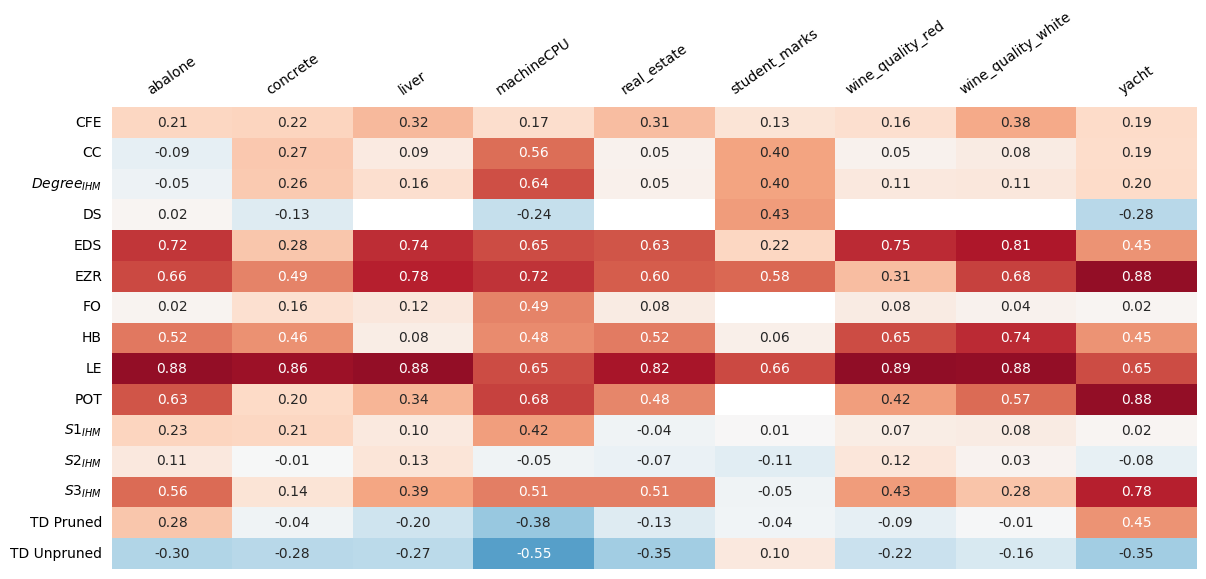

In [ ]:
df_styled = all_correlations_df\
    .set_index("dataset")\
    .T.sort_index()\
    .rename(index=feature_mapping_name_latex).round(4)

fig, ax = plt.subplots(figsize=(14, 6))
heatmap = sns.heatmap(
    df_styled, 
    annot=True,
    cmap="RdBu_r",
    cbar = False,
    fmt='.2f',
    vmin=-1.0,
    vmax=1.0,
    # linewidth=.1
)

# Rotate x-axis labels
plt.xticks(rotation=45)
plt.yticks(rotation=0)
# heatmap.set_title("Correlation between HM and IH")
heatmap.set_xlabel("", labelpad=20)
heatmap.xaxis.set_label_position("top")
heatmap.xaxis.set_tick_params(labelsize=10, rotation=35)
heatmap.xaxis.tick_top()
# Remove os ticks
heatmap.tick_params(bottom = False, left=False, top = False)
fig.savefig('img/hm_and_ih_correlations.png', dpi=300)

### IH for Train

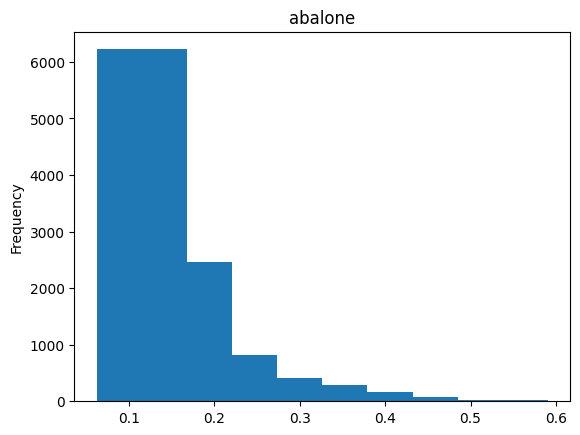

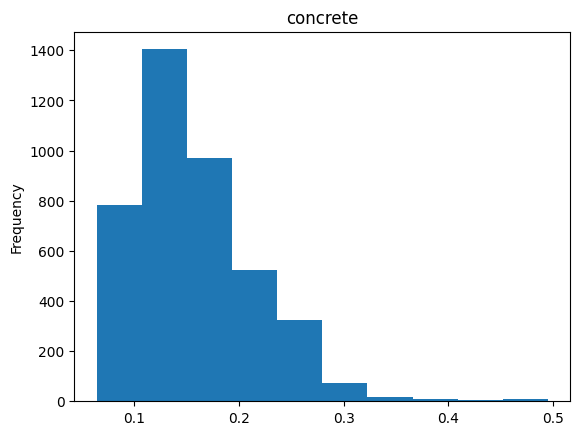

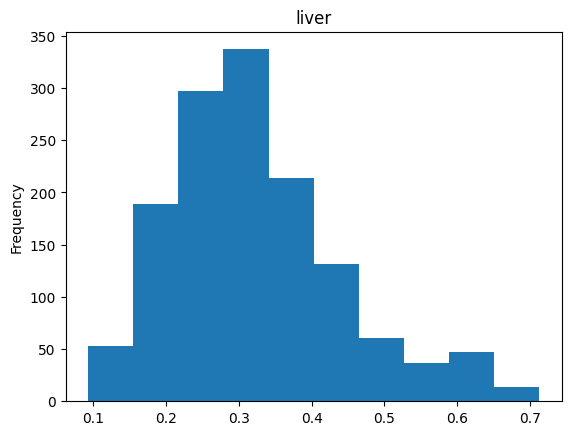

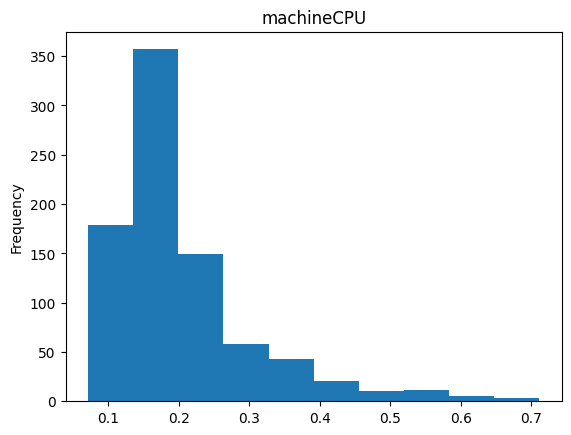

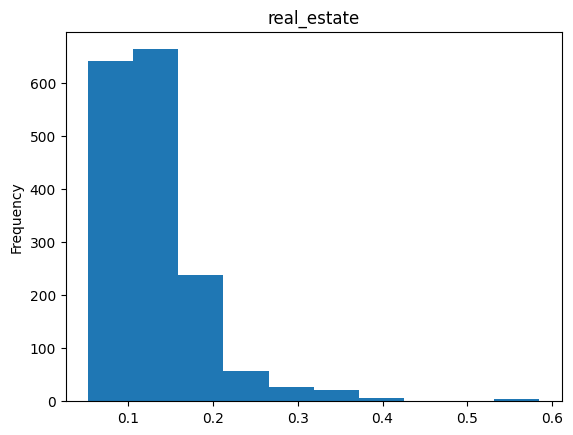

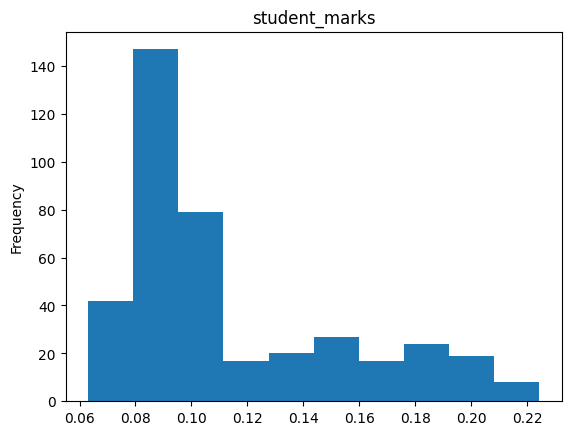

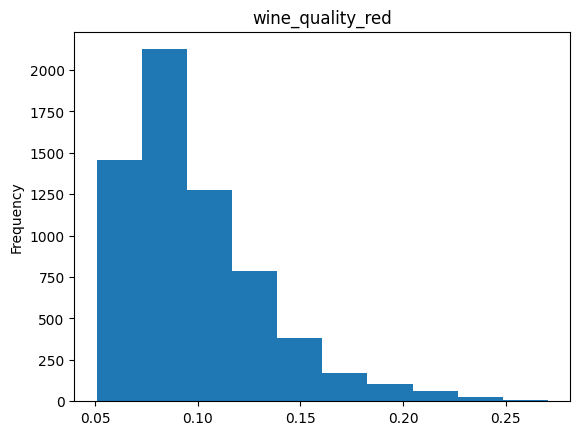

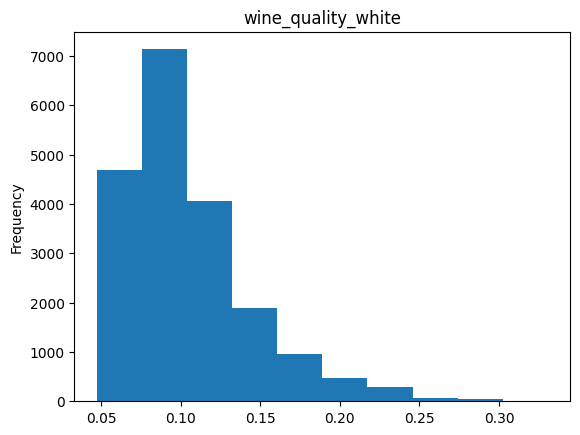

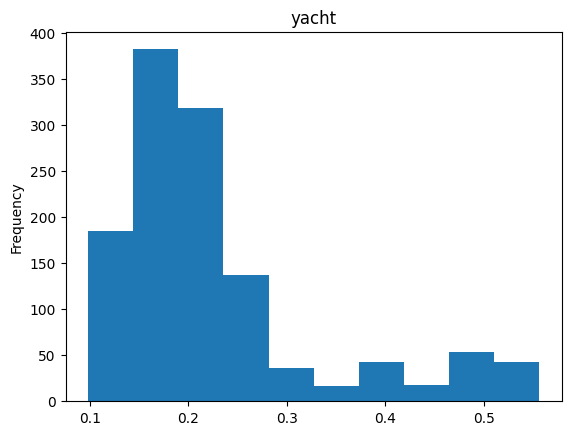

In [15]:
# plot instance hardness histogram
for name, all_measures in all_meta_features_dict.items():
    fig, ax = plt.subplots()
    all_measures['instance_hardness']['instance_hardness'].plot(kind='hist', ax=ax)
    ax.set_title(name)
    plt.show()


### IH for Test

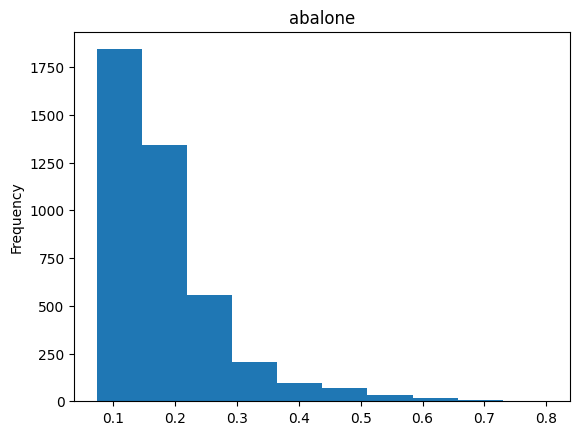

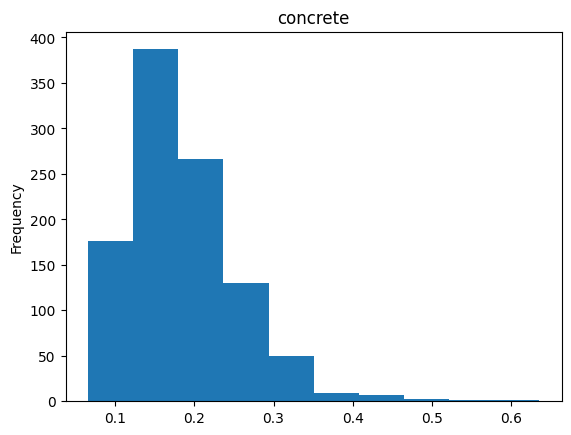

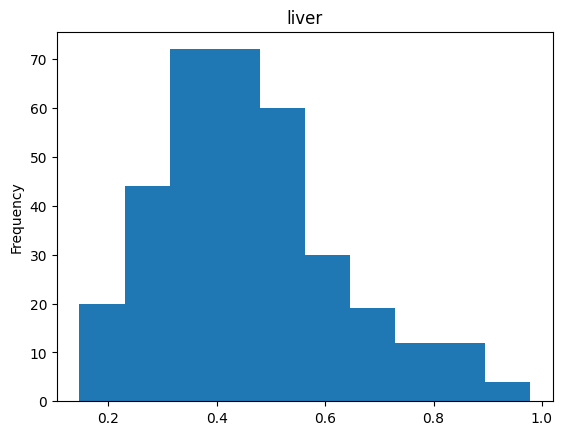

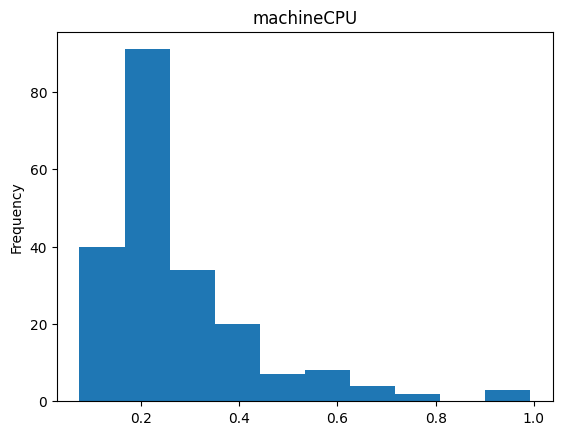

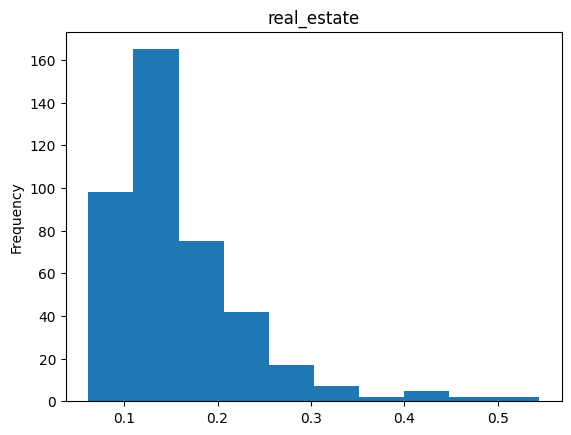

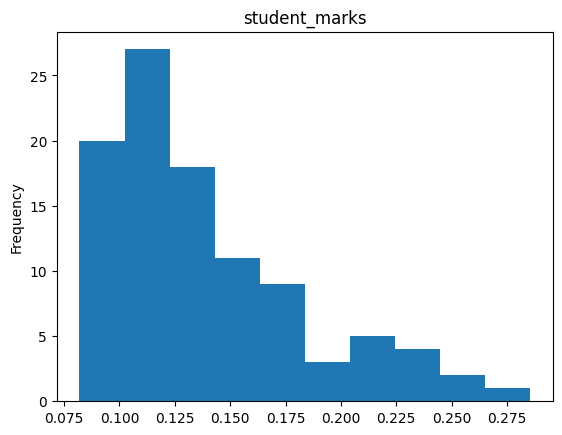

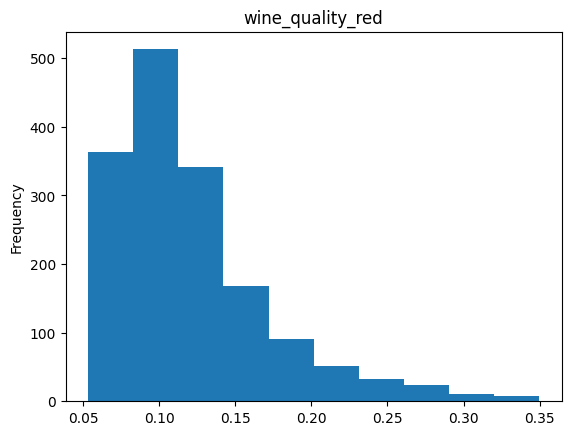

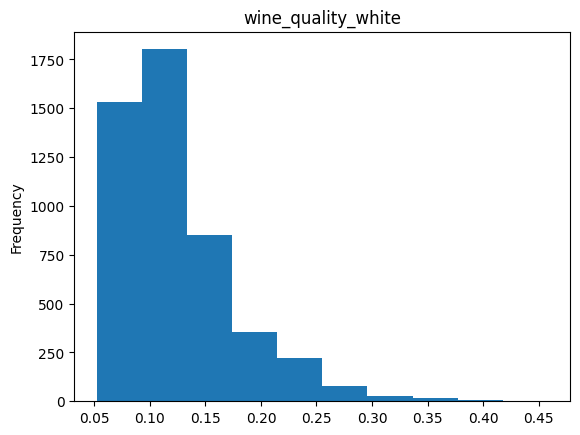

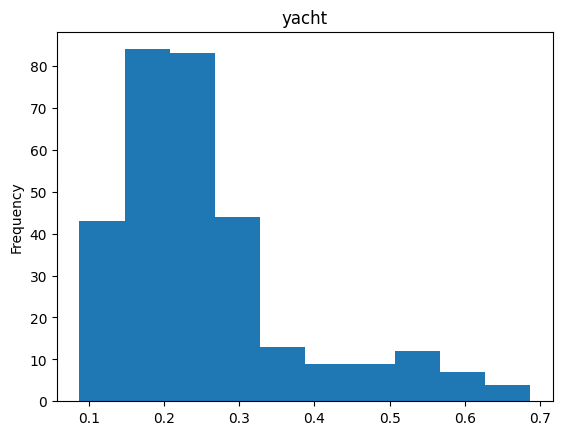

In [16]:
# plot instance hardness histogram
for name, all_measures in all_meta_features_test_dict.items():
    fig, ax = plt.subplots()
    all_measures['instance_hardness']['instance_hardness'].plot(kind='hist', ax=ax)
    ax.set_title(name)
    plt.show()


## Reproducing article results

In [17]:
regressors_list = [
    linear_model.Lasso(), 
    linear_model.Ridge(), 
    KNeighborsRegressor(), 
    SVR(), 
    DecisionTreeRegressor()
]

ensemble = DESRegression(
    regressors_list=regressors_list,
    random_state=0,
    n_estimators_bag=20,
    competence_region='knn',
    k=5,
    competence_level=em.all_errors,
    include_instance_hardness=False
)


article_results = run_experiment_with_timeout('yacht', baseline_model=ensemble, challenger_experiments={})

========== Processing yacht - Fold 1 ==========
Running baseline model...
========== Processing yacht - Fold 2 ==========
Running baseline model...
========== Processing yacht - Fold 3 ==========
Running baseline model...
========== Processing yacht - Fold 4 ==========
Running baseline model...
========== Processing yacht - Fold 5 ==========
Running baseline model...


In [18]:
article_results_df = get_df_results(article_results)
article_agg_results = get_agg_results(article_results_df)
article_agg_results

mse              r2             mae            rmse         \
               mean     std    mean     std    mean     std    mean    std   
model_name                                                                   
baseline    40.6294  8.2427  0.8228  0.0165  3.6831  0.3035  6.3478  0.647   

              mape         execution_time                   
              mean     std           mean     std      sum  
model_name                                                  
baseline    2.6107  1.1035         2.7965  0.1064  13.9823

## Create ensembles

In [19]:
regressors_list = [
    linear_model.Lasso(), 
    linear_model.Ridge(), 
    KNeighborsRegressor(), 
    SVR(), 
    DecisionTreeRegressor()
]

ensemble = DESRegression(
    regressors_list=regressors_list,
    random_state=0,
    n_estimators_bag=20,
    competence_region='knn',
    k=5,
    competence_level=em.all_errors,
    include_instance_hardness=False
)

drs_baseline = DESRegression(
    regressors_list=regressors_list,
    random_state=0,
    n_estimators_bag=20,
    competence_region='knn',
    k=5,
    competence_level=em.all_errors,
    include_instance_hardness=False,
    ensemble_type='DRS'
)

ensemble_ih = DESRegression(
    regressors_list = regressors_list,
    random_state=0,
    n_estimators_bag=20,
    competence_region='knn',
    k=5,
    competence_level=em.sum_absolute_error_weighted,
    include_instance_hardness=True,
    include_hardness_measures=False,
    hardness_measures_list=None,
    meta_feature='instance_hardness'
)

ensemble_hm = DESRegression(
    regressors_list = regressors_list,
    random_state=0,
    n_estimators_bag=20,
    competence_region='knn',
    k=5,
    competence_level=em.sum_absolute_error_weighted,
    include_instance_hardness=False,
    include_hardness_measures=True,
    hardness_measures_list=['S1','S2','S3', 'D', 'L1', 'EZR', 'EDS'],
    meta_feature='S2'
)

linear_reg = linear_model.LinearRegression()
challenger_experiments = {
    'ensemble_ih': {
        "model": ensemble_ih,
        "params": {
            "include_hardness_measures": False,
            "include_instance_hardness": True,
            "meta_feature": "instance_hardness"
        }
    },
    'ensemble_hm_s2': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "S2",
            # "hardness_measures_list": ["S2"]
        }
    },
    'ensemble_hm_s1': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "S1",
            # "hardness_measures_list": ["S1"]
        }
    },
    'ensemble_hm_s3': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "S3",
            # "hardness_measures_list": ["S3"]
        }
    },
    'ensemble_hm_d': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "D",
            # "hardness_measures_list": ["D"]
        }
    },
    'ensemble_hm_l1': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "L1",
            # "hardness_measures_list": ["L1"]
        }
    },
    'ensemble_hm_ezr': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "EZR",
            # "hardness_measures_list": ["EZR"]
        }
    },
    'ensemble_hm_eds': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "EDS",
            # "hardness_measures_list": ["EDS"]
        }
    },
    'linear_reg': {
        "model": linear_reg,
    }
}

## Yacht Dataset

### DES models

In [20]:
from ensemble_versions import des_challenger_experiments

des_yacht_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=ensemble, 
    challenger_experiments=des_challenger_experiments
)

========== Processing yacht - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: des_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: des_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


In [21]:
des_yacht_results_df = get_df_results(des_yacht_results)
des_yacht_agg_results = get_agg_results(des_yacht_results_df)
des_yacht_agg_results

mse              r2             mae            rmse  \
                     mean     std    mean     std    mean     std    mean   
model_name                                                                  
baseline          40.6294  8.2427  0.8228  0.0165  3.6831  0.3035  6.3478   
des_ensemble_d    26.3645  7.2546  0.8860  0.0192  2.9086  0.3549  5.0926   
des_ensemble_eds  28.4893  5.1189  0.8731  0.0274  2.9843  0.4487  5.3197   
des_ensemble_ezr  37.5655  6.3252  0.8315  0.0430  3.4452  0.4716  6.1108   
des_ensemble_ih   27.2230  7.2267  0.8812  0.0223  2.9612  0.3180  5.1832   
des_ensemble_l1   26.5614  4.2285  0.8828  0.0162  2.8786  0.3903  5.1410   
des_ensemble_s1   27.9890  8.7300  0.8794  0.0251  2.9772  0.4624  5.2332   
des_ensemble_s2   26.3888  7.0605  0.8856  0.0193  2.9141  0.3452  5.0971   
des_ensemble_s3   37.7951  4.9997  0.8314  0.0332  3.4397  0.4000  6.1364   

                            mape         execution_time                   
                     std    mean     std           mean     std      sum  
model_name                                                                
baseline          0.6470  2.6107  1.1035         2.7415  0.0452  13.7075  
des_ensemble_d    0.7335  2.1841  1.2274         2.5637  0.0195  12.8185  
des_ensemble_eds  0.4869  2.0262  1.2446         2.5814  0.0408  12.9069  
des_ensemble_ezr  0.5280  2.0821  1.3956         2.5702  0.0360  12.8508  
des_ensemble_ih   0.6686  2.0757  1.1443         3.6656  0.0493  18.3280  
des_ensemble_l1   0.4055  1.9887  0.8944         2.5606  0.0268  12.8031  
des_ensemble_s1   0.8677  2.1019  1.2314         2.5659  0.0243  12.8294  
des_ensemble_s2   0.7146  2.1758  1.2335         2.5618  0.0228  12.8089  
des_ensemble_s3   0.4177  1.7984  0.8973         2.5811  0.0184  12.9056

### DRS models

In [23]:
from ensemble_versions import drs_challenger_experiments, drs_baseline_ensemble

drs_yacht_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)

========== Processing yacht - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [24]:
drs_yacht_results_df = get_df_results(drs_yacht_results)
drs_yacht_agg_results = get_agg_results(drs_yacht_results_df)
drs_yacht_agg_results

mse               r2             mae            rmse  \
                     mean      std    mean     std    mean     std    mean   
model_name                                                                   
baseline          56.8682  17.2169  0.7420  0.0998  3.1057  0.6908  7.4702   
drs_ensemble_d     2.0454   1.2065  0.9914  0.0043  0.7258  0.2156  1.3802   
drs_ensemble_eds   2.0405   1.2097  0.9914  0.0043  0.7229  0.2175  1.3782   
drs_ensemble_ezr   2.0406   1.2098  0.9914  0.0043  0.7228  0.2175  1.3782   
drs_ensemble_ih    2.0454   1.2065  0.9914  0.0043  0.7258  0.2156  1.3802   
drs_ensemble_l1    2.0454   1.2065  0.9914  0.0043  0.7258  0.2156  1.3802   
drs_ensemble_s1    2.0454   1.2065  0.9914  0.0043  0.7258  0.2156  1.3802   
drs_ensemble_s2    2.0454   1.2065  0.9914  0.0043  0.7258  0.2156  1.3802   
drs_ensemble_s3    2.0404   1.2097  0.9914  0.0043  0.7229  0.2178  1.3782   

                            mape         execution_time                   
                     std    mean     std           mean     std      sum  
model_name                                                                
baseline          1.1532  1.3151  0.8248         3.5009  2.4383  17.5046  
drs_ensemble_d    0.4188  0.2166  0.0559         2.2274  0.0402  11.1369  
drs_ensemble_eds  0.4200  0.2163  0.0559         2.3632  0.1612  11.8158  
drs_ensemble_ezr  0.4201  0.2162  0.0557         2.3007  0.1222  11.5035  
drs_ensemble_ih   0.4188  0.2166  0.0559         3.5157  0.3167  17.5785  
drs_ensemble_l1   0.4188  0.2166  0.0559         2.3300  0.1164  11.6499  
drs_ensemble_s1   0.4188  0.2166  0.0559         2.2467  0.0205  11.2334  
drs_ensemble_s2   0.4188  0.2166  0.0559         2.2011  0.0310  11.0057  
drs_ensemble_s3   0.4200  0.2103  0.0561         2.2728  0.1306  11.3640

### SE Models

In [60]:
from ensemble_versions import se_challenger_experiments, se_baseline_ensemble

se_yacht_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)

desReg.des.DESRegression - INFO - Calculating instance hardness


========== Processing yacht - Fold 1 ==========
Running baseline model...
Running challenger model: se_ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: se_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


Running challenger model: se_ensemble_s2...


... (48 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: se_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: se_ensemble_ezr...


In [61]:

se_yacht_results_df = get_df_results(se_yacht_results)
se_yacht_agg_results = get_agg_results(se_yacht_results_df)
se_yacht_agg_results

mse              r2             mae            rmse  \
                    mean     std    mean     std    mean     std    mean   
model_name                                                                 
baseline         86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_d    86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_eds  86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_ezr  86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_ih   86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_l1   86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_s1   86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_s2   86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   
se_ensemble_s3   86.7589  20.018  0.6237  0.0376  5.5961  0.6016  9.2629   

                           mape         execution_time                  
                    std    mean     std           mean     std     sum  
model_name                                                              
baseline         1.0937  3.6589  1.3021         0.0838  0.0167  0.4192  
se_ensemble_d    1.0937  3.6589  1.3021         0.1925  0.0081  0.9627  
se_ensemble_eds  1.0937  3.6589  1.3021         0.1967  0.0053  0.9836  
se_ensemble_ezr  1.0937  3.6589  1.3021         0.1956  0.0083  0.9780  
se_ensemble_ih   1.0937  3.6589  1.3021         1.2511  0.1201  6.2553  
se_ensemble_l1   1.0937  3.6589  1.3021         0.1960  0.0101  0.9801  
se_ensemble_s1   1.0937  3.6589  1.3021         0.2621  0.0358  1.3104  
se_ensemble_s2   1.0937  3.6589  1.3021         0.2040  0.0264  1.0201  
se_ensemble_s3   1.0937  3.6589  1.3021         0.1963  0.0108  0.9815

## yatch

In [283]:
yatch_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing yacht - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [284]:
yatch_results_df = get_df_results(yatch_results)
yatch_agg_results = get_agg_results(yatch_results_df)
yatch_agg_results

mse              r2             mae            rmse  \
                    mean     std    mean     std    mean     std    mean   
model_name                                                                 
baseline         40.7130  8.2810  0.8225  0.0164  3.6823  0.2994  6.3541   
ensemble_hm_d    26.4374  7.2469  0.8856  0.0192  2.9111  0.3524  5.0998   
ensemble_hm_eds  28.5591  5.0548  0.8728  0.0271  2.9878  0.4425  5.3268   
ensemble_hm_ezr  37.6469  6.2868  0.8311  0.0429  3.4477  0.4705  6.1178   
ensemble_hm_l1   26.6500  4.1889  0.8824  0.0160  2.8810  0.3866  5.1499   
ensemble_hm_s1   28.0807  8.7638  0.8790  0.0253  2.9792  0.4596  5.2417   
ensemble_hm_s2   26.4777  7.0794  0.8852  0.0194  2.9163  0.3430  5.1056   
ensemble_hm_s3   37.8793  4.7791  0.8310  0.0326  3.4405  0.3894  6.1444   
ensemble_ih      27.7378  7.8977  0.8793  0.0240  2.9681  0.3450  5.2274   
linear_reg       79.5926  9.6234  0.6496  0.0253  7.2047  0.2138  8.9085   

                            mape         execution_time                   
                    std     mean     std           mean     std      sum  
model_name                                                                
baseline         0.6501   2.6106  1.1027         2.3936  0.1236  11.9678  
ensemble_hm_d    0.7327   2.1839  1.2269         2.1508  0.0282  10.7540  
ensemble_hm_eds  0.4795   2.0269  1.2459         2.1683  0.0914  10.8413  
ensemble_hm_ezr  0.5238   2.0816  1.3947         2.1705  0.0664  10.8526  
ensemble_hm_l1   0.4010   1.9884  0.8932         2.1273  0.0301  10.6363  
ensemble_hm_s1   0.8698   2.1014  1.2310         2.2497  0.1686  11.2484  
ensemble_hm_s2   0.7160   2.1754  1.2328         2.1879  0.1140  10.9396  
ensemble_hm_s3   0.3971   1.7976  0.8960         2.1333  0.0226  10.6666  
ensemble_ih      0.7180   2.1269  1.2028         3.8377  0.3943  19.1887  
linear_reg       0.5384  14.8792  7.0780         0.0007  0.0004   0.0036

In [17]:
def calculate_prediction_residual(baseline_pred, model_pred):
    residual = (baseline_pred - model_pred)/baseline_pred
    return residual

In [21]:
consolidated_meta_features_test['yacht'].shape

(308, 48)

In [97]:
def compile_data_and_meta_data(predictions_df, ih_data, hm_data):
    baseline_predictions = predictions_df\
        .query("model_name == 'baseline'")\
        .rename(columns={'y_pred': 'baseline_prediction', 'y_true': 'baseline_true'})\
        [['partition', 'baseline_prediction', 'baseline_true']]

    exploded_df = \
        predictions_df\
        .merge(baseline_predictions, on=['partition'])\
        .explode(['y_pred', 'y_true', 'baseline_prediction', 'baseline_true']).reset_index(drop=True)
    
    list_df = list()
    for model_name in exploded_df['model_name'].unique():
        model_df = exploded_df.query("model_name == @model_name").reset_index(drop=True)
        tmp_df = pd.concat([
            model_df,
            ih_data,
            hm_data
        ], axis=1)
        list_df.append(tmp_df)
    all_data = pd.concat(list_df, ignore_index=True)
    return all_data

In [127]:
yacht_all_data = compile_data_and_meta_data(
    predictions_df=yatch_results_df, 
    ih_data=all_meta_features_test_dict['yacht']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['yacht']['hardness_measures']
)

yacht_all_data['baseline_residual'] = \
    (yacht_all_data['baseline_prediction'] - yacht_all_data['y_pred'])/yacht_all_data['baseline_prediction']
yacht_all_data['target_residual'] = \
    (yacht_all_data['y_true'] - yacht_all_data['y_pred'])/yacht_all_data['y_true']
ih_bucket_labels = ['0-0.1', '0.1-0.2', '0.2-0.3', '0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7-0.8', '0.8-0.9', '0.9-1.0']

yacht_all_data['instance_hardness_bin'] = pd.cut(
    yacht_all_data['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    labels=ih_bucket_labels, 
    include_lowest=True
).astype("str")

residual_buckets_labels = ['[-inf, -1]', '[-1, -0.5]', '[-0.5, 0]', '[0, 0.5]', '[0.5, 1]', '[1, inf]']
yacht_all_data['target_residual_bin'] = pd.cut(
    yacht_all_data['target_residual'], 
    bins=[-np.inf, -1, -0.5, 0, 0.5, 1.0, np.inf], 
    labels=residual_buckets_labels, 
    include_lowest=True
).astype("str")

yacht_all_data['squared_error'] = (yacht_all_data['y_true'] - yacht_all_data['y_pred']) ** 2
yacht_all_data.head()

,mse,r2,mae,rmse,mape,execution_time,y_pred,y_true,status,model_name,partition,baseline_prediction,baseline_true,instance_hardness,V0,V1,V2,V3,V4,V5,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U,baseline_residual,target_residual,instance_hardness_bin,target_residual_bin,squared_error
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.296429,0.11,success,baseline,1,1.296429,0.11,0.336416,-2.3,0.568,4.78,3.99,3.17,0.125,0.11,1.000000,0.993192,0.882736,0.548223,0.113025,0.013070,0.0,0.480519,0.382074,0,0.098165,0.619947,1.897346e-03,0.75,0.823529,0.0,-10.785715,0.3-0.4,"[-inf, -1]",1.407613
1,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.259244,0.27,success,baseline,1,1.259244,0.27,0.246059,-2.3,0.568,4.78,3.99,3.17,0.150,0.27,1.000000,0.993029,0.863192,0.548223,0.103010,0.011701,0.0,0.480519,0.299684,0,0.012821,0.701633,1.091123e-03,0.75,0.941176,0.0,-3.663865,0.2-0.3,"[-inf, -1]",0.978603
2,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.481672,0.47,success,baseline,1,1.481672,0.47,0.115157,-2.3,0.568,4.78,3.99,3.17,0.175,0.47,1.000000,0.992859,0.843648,0.548223,0.091037,0.010095,0.0,0.480519,0.193667,0,0.012821,0.677125,3.946838e-04,0.75,0.764706,0.0,-2.152493,0.1-0.2,"[-inf, -1]",1.02348
3,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.726464,0.78,success,baseline,1,1.726464,0.78,0.084610,-2.3,0.568,4.78,3.99,3.17,0.200,0.78,0.857143,0.992741,0.830619,0.548223,0.073742,0.007836,0.0,0.480519,0.056340,0,0.012821,0.666275,3.012436e-07,0.75,0.941176,0.0,-1.213415,0-0.1,"[-inf, -1]",0.895793
4,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,2.043427,1.18,success,baseline,1,2.043427,1.18,0.100300,-2.3,0.568,4.78,3.99,3.17,0.225,1.18,1.000000,0.992649,0.820847,0.548223,0.053839,0.005339,0.0,0.480519,0.103001,0,0.012821,0.683648,1.508886e-03,0.75,0.705882,0.0,-0.731718,0.1-0.2,"[-1, -0.5]",0.745506


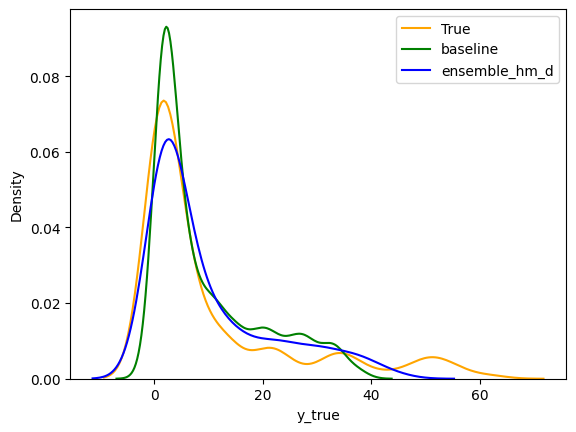

In [92]:
fig = sns.kdeplot(
    data=yacht_all_data.query("model_name != 'linear_reg'"),
    x='y_true',
    color='orange',
    label='True'
)

fig = sns.kdeplot(
    data=yacht_all_data,
    x='baseline_prediction',
    color='g',
    label='baseline'
)


fig = sns.kdeplot(
    data=yacht_all_data.query("model_name == 'ensemble_hm_d'"),
    x='y_pred',
    color='b',
    label='ensemble_hm_d'
)

plt.legend()


In [307]:
avg_residual_per_ih = \
    yacht_all_data.groupby(by=['model_name', 'instance_hardness_bin'])\
    .agg(
        avg_baseline_residual = ("baseline_residual", "mean"),
        std_baseline_residual = ("baseline_residual", "std"),
        avg_y_true = ("y_true", "mean"),
        avg_target_residual = ("target_residual", "mean"),
        std_target_residual = ("target_residual", "std"),
        avg_squared_error = ("squared_error", "mean"),
    )\
    .reset_index()\
    .dropna()


KeyError: 'instance_hardness_bin'

In [ ]:

sns.barplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_bin',
    y='avg_baseline_residual',
    hue='model_name',

)


<Axes: xlabel='instance_hardness_bin', ylabel='avg_target_residual'>

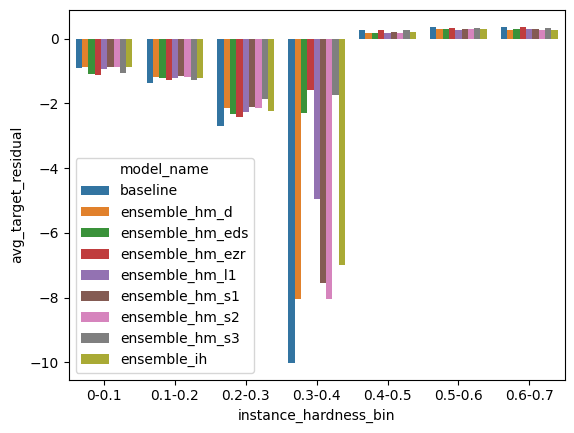

In [114]:
sns.barplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_bin',
    y='avg_target_residual',
    hue='model_name',

)

<Axes: xlabel='instance_hardness_bin', ylabel='target_residual'>

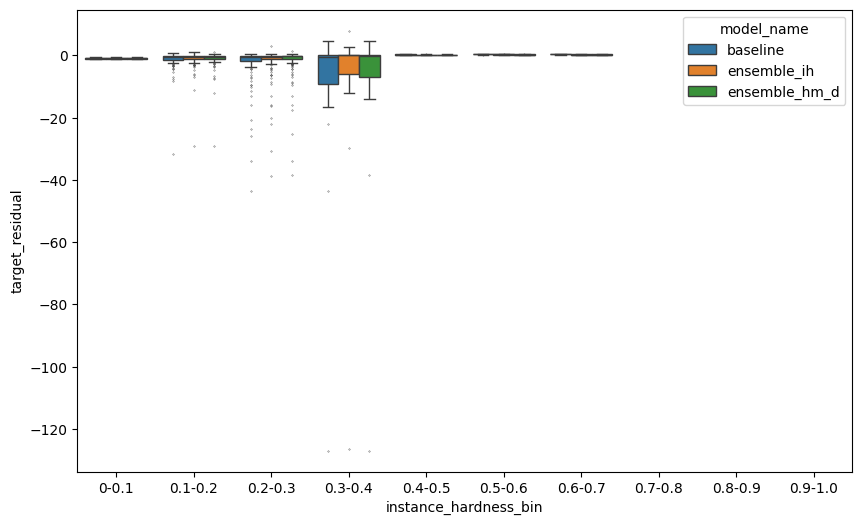

In [121]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=yacht_all_data.query("model_name in ['baseline', 'ensemble_ih', 'ensemble_hm_d']"),
    x='instance_hardness_bin',
    y='target_residual',
    hue='model_name',
    order=ih_bucket_labels,
    fliersize=0.3,
    whis = 1.2,
)

Text(0, 0.5, 'MSE')

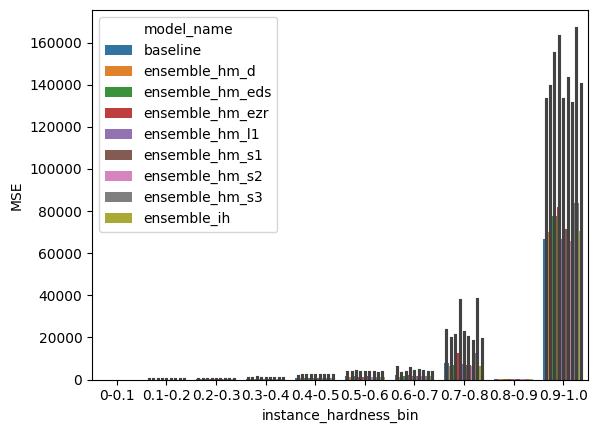

In [306]:
sns.barplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_bin',
    y='avg_squared_error',
    hue='model_name',
)

plt.ylabel("MSE")
# plt.xlabel("Instance Hardness")

<Axes: xlabel='instance_hardness_bin', ylabel='std_target_residual'>

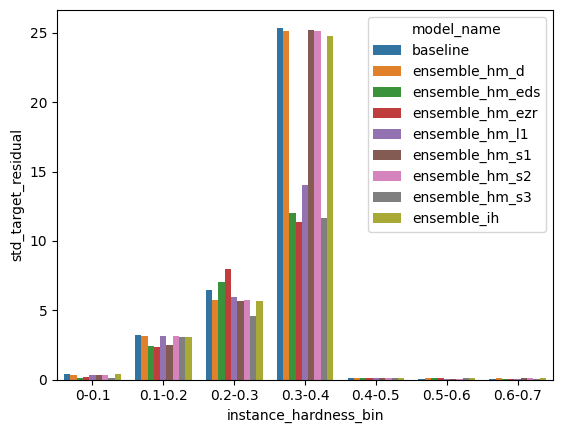

In [110]:
sns.barplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_bin',
    y='std_target_residual',
    hue='model_name'
)

<Axes: xlabel='y_true', ylabel='instance_hardness'>

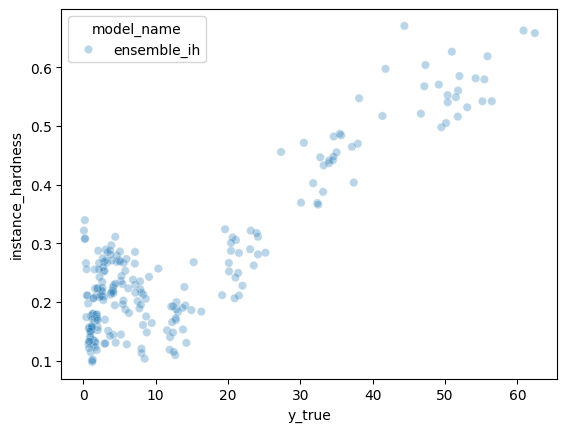

In [152]:
sns.scatterplot(
    data=yacht_all_data.query("model_name == 'ensemble_ih' and abs(target_residual) <= 1"),
    x='y_true',
    y='instance_hardness',
    hue='model_name',
    alpha=0.3
)

<Axes: xlabel='target_residual', ylabel='instance_hardness'>

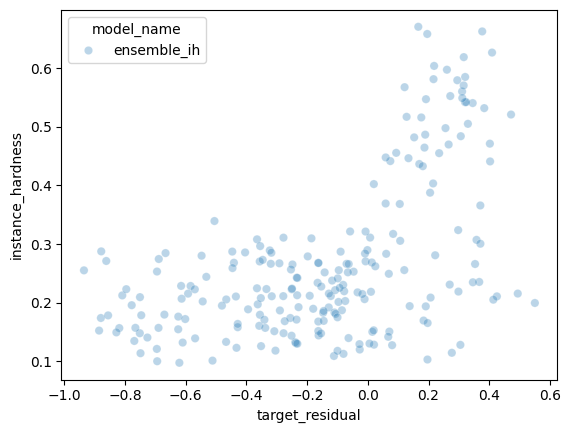

In [153]:
sns.scatterplot(
    data=yacht_all_data.query("model_name == 'ensemble_ih' and abs(target_residual) <= 1"),
    x='target_residual',
    y='instance_hardness',
    hue='model_name',
    alpha=0.3
)

<Axes: xlabel='target_residual_bin', ylabel='avg_ih'>

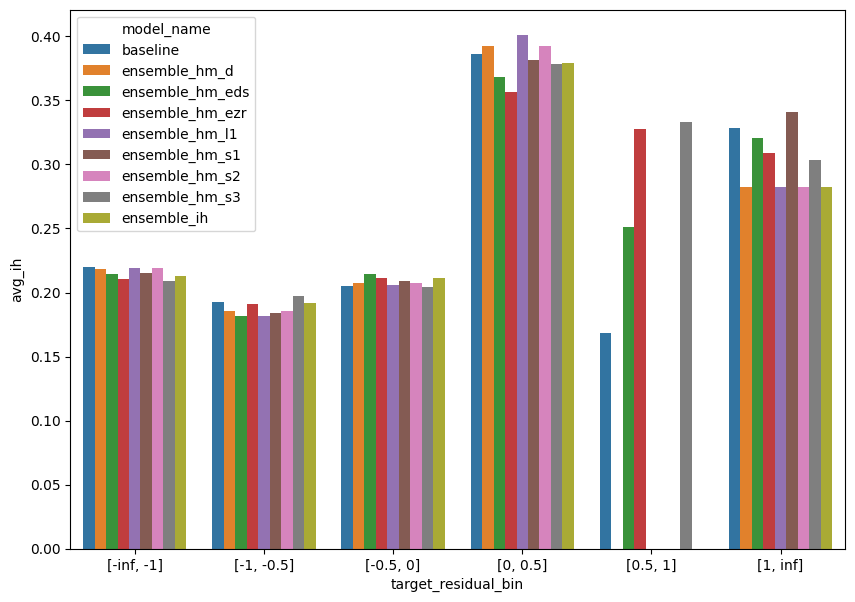

In [137]:
fig, ax = plt.subplots(figsize=(10, 7))
avg_ih_per_residual = \
    yacht_all_data.groupby(by=['model_name', 'target_residual_bin'])\
    .agg(
        avg_ih = ("instance_hardness", "mean"),
        std_ih = ("instance_hardness", "std"),
    )\
    .reset_index()\
    .dropna()

sns.barplot(
    data=avg_ih_per_residual.query("model_name != 'linear_reg'"),
    x='target_residual_bin',
    y='avg_ih',
    hue='model_name',
    order=residual_buckets_labels
)

In [96]:
yacth_test_predictions = pd.DataFrame()
for part in yatch_results:
    for model in yatch_results[part].keys():
        new_df = pd.DataFrame(yatch_results[part][model])\
            [['y_pred', 'y_true']]\
            .assign(dataset="yacth")\
            .assign(model_name=model)\
            .assign(partition=part)
        yacth_test_predictions = pd.concat([
            yacth_test_predictions, 
            new_df
        ], ignore_index=True)

In [97]:
list_df = list()
for model in yacth_test_predictions['model_name'].unique():
    model_df = yacth_test_predictions.query("model_name == @model").reset_index(drop=True)
    # Concatenate horizontally (axis=1) instead of vertically
    tmp_df = pd.concat([
        model_df, 
        all_meta_features_test_dict['yacht']['instance_hardness'][['instance_hardness']],
        all_meta_features_test_dict['yacht']['hardness_measures'],
    ], axis=1)  # Changed from axis=0 to axis=1
    list_df.append(tmp_df)
concatenated_df = pd.concat(list_df, ignore_index=True)

In [98]:
concatenated_df['error_abs'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred'])
concatenated_df['error_rel'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred']) / concatenated_df['y_true']
concatenated_df['error_rel_sq'] = \
    (concatenated_df['y_true'] - concatenated_df['y_pred']) ** 2 / concatenated_df['y_true'] ** 2
concatenated_df['instance_hardness_bin'] = pd.cut(
    concatenated_df['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    include_lowest=True
)

In [78]:
avg_residual_per_ih = \
    concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\
    .agg(
        avg_error_rel = ("error_rel", "mean"),
        std_error_rel = ("error_rel", "std")
    )\
    .reset_index()\
    .dropna()

sns.lineplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_str_bin',
    y='avg_error_rel',
    hue='model_name'
)


NameError: name 'concatenated_df' is not defined

## Student marks

In [25]:
student_marks_results = run_experiment_with_timeout(
    'student_marks', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing student_marks - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [159]:
student_marks_results_df = get_df_results(student_marks_results)
student_marks_agg_results = get_agg_results(student_marks_results_df)

student_marks_agg_results

mse              r2             mae            rmse  \
                    mean     std    mean     std    mean     std    mean   
model_name                                                                 
baseline          2.3477  1.5707  0.9879  0.0074  1.0342  0.2900  1.4690   
ensemble_hm_d     1.7898  1.3612  0.9909  0.0065  0.9058  0.2783  1.2657   
ensemble_hm_eds   1.9702  1.3241  0.9898  0.0063  0.9697  0.2356  1.3480   
ensemble_hm_ezr   2.0112  1.5641  0.9898  0.0074  0.9904  0.3525  1.3372   
ensemble_hm_l1    1.8284  1.3541  0.9907  0.0065  0.9219  0.3039  1.2813   
ensemble_hm_s1    1.8526  1.3874  0.9905  0.0066  0.9174  0.2798  1.2902   
ensemble_hm_s2    1.7737  1.3172  0.9909  0.0063  0.9012  0.2747  1.2642   
ensemble_hm_s3    2.1125  1.5258  0.9893  0.0071  1.0134  0.3278  1.3801   
ensemble_ih       1.8116  1.3860  0.9908  0.0066  0.9080  0.2981  1.2720   
linear_reg       12.9917  2.0016  0.9296  0.0123  3.1464  0.3314  3.5964   

                           mape         execution_time                  
                    std    mean     std           mean     std     sum  
model_name                                                              
baseline         0.4871  0.0514  0.0119         1.7168  2.0645  8.5838  
ensemble_hm_d    0.4845  0.0444  0.0082         0.8165  0.0395  4.0827  
ensemble_hm_eds  0.4376  0.0462  0.0166         0.7956  0.0145  3.9778  
ensemble_hm_ezr  0.5282  0.0506  0.0107         0.8124  0.0303  4.0622  
ensemble_hm_l1   0.4829  0.0450  0.0086         0.8217  0.0491  4.1086  
ensemble_hm_s1   0.4846  0.0448  0.0099         0.7987  0.0205  3.9933  
ensemble_hm_s2   0.4682  0.0445  0.0094         0.9519  0.3276  4.7593  
ensemble_hm_s3   0.5097  0.0513  0.0134         0.7956  0.0205  3.9780  
ensemble_ih      0.4918  0.0442  0.0087         1.3777  0.0298  6.8885  
linear_reg       0.2681  0.1937  0.0377         0.0005  0.0001  0.0025

In [102]:
student_marks_test_predictions = pd.DataFrame()
for part in student_marks_results:
    for model in student_marks_results[part].keys():
        new_df = pd.DataFrame(student_marks_results[part][model])\
            [['y_pred', 'y_true']]\
            .assign(dataset="student_marks")\
            .assign(model_name=model)\
            .assign(partition=part)
        student_marks_test_predictions = pd.concat([
            student_marks_test_predictions, 
            new_df
        ], ignore_index=True)

In [103]:
list_df = list()
for model in student_marks_test_predictions['model_name'].unique():
    model_df = student_marks_test_predictions.query("model_name == @model").reset_index(drop=True)
    # Concatenate horizontally (axis=1) instead of vertically
    tmp_df = pd.concat([
        model_df, 
        all_meta_features_test_dict['yacht']['instance_hardness'][['instance_hardness']],
        all_meta_features_test_dict['yacht']['hardness_measures'],
    ], axis=1)  # Changed from axis=0 to axis=1
    list_df.append(tmp_df)
concatenated_df = pd.concat(list_df, ignore_index=True)
concatenated_df['error_abs'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred'])
concatenated_df['error_rel'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred']) / concatenated_df['y_true']
concatenated_df['error_rel_sq'] = \
    (concatenated_df['y_true'] - concatenated_df['y_pred']) ** 2 / concatenated_df['y_true'] ** 2
concatenated_df['instance_hardness_bin'] = pd.cut(
    concatenated_df['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    include_lowest=True
)

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_3078/3168568460.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


<Axes: xlabel='instance_hardness_str_bin', ylabel='avg_error_rel'>

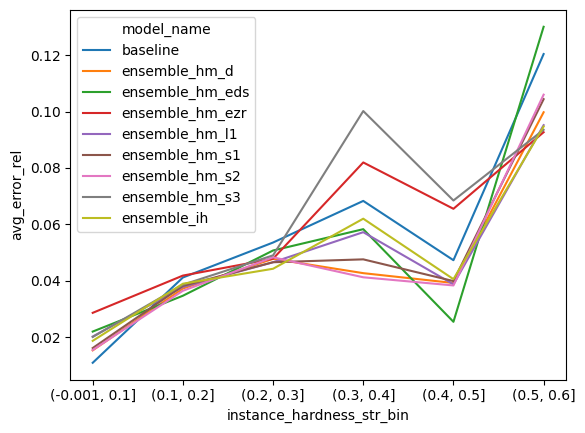

In [104]:
avg_residual_per_ih = \
    concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\
    .agg(
        avg_error_rel = ("error_rel", "mean"),
        std_error_rel = ("error_rel", "std")
    )\
    .reset_index()\
    .dropna()\
    .assign(instance_hardness_str_bin = lambda x: x['instance_hardness_bin'].astype(str))


sns.lineplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_str_bin',
    y='avg_error_rel',
    hue='model_name'
)


## Liver

In [161]:
liver_results = run_experiment_with_timeout(
    'liver', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing liver - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [162]:
liver_results_df = get_df_results(liver_results)
liver_agg_results = get_agg_results(liver_results_df)
liver_agg_results

mse               r2               mae            rmse  \
                    mean     std     mean       std    mean     std    mean   
model_name                                                                    
baseline         12.3692  7.7322 -52.9900  110.5042  2.8684  0.8324  3.3675   
ensemble_hm_d    12.5489  7.5462 -56.0179  116.7053  2.8815  0.8083  3.4045   
ensemble_hm_eds  12.7187  7.4603 -56.8784  118.3361  2.9272  0.8002  3.4334   
ensemble_hm_ezr  12.7306  7.4443 -58.0975  121.0898  2.9146  0.8031  3.4354   
ensemble_hm_l1   12.7919  7.5340 -57.8571  120.5570  2.9368  0.8054  3.4428   
ensemble_hm_s1   12.5494  7.5111 -55.1682  114.7832  2.8898  0.8029  3.4068   
ensemble_hm_s2   12.5971  7.4661 -55.8728  116.2264  2.9026  0.8001  3.4154   
ensemble_hm_s3   12.8388  7.2856 -57.6555  119.7545  2.9450  0.7854  3.4570   
ensemble_ih      12.7959  7.4745 -57.0112  118.5011  2.9335  0.7950  3.4458   
linear_reg       12.0645  6.4937 -56.4142  117.7328  2.8015  0.7893  3.3642   

                                 mape               execution_time          \
                    std          mean           std           mean     std   
model_name                                                                   
baseline         1.1343  3.690752e+14  6.562521e+14         2.5821  0.0713   
ensemble_hm_d    1.0945  3.716721e+14  6.657005e+14         2.3210  0.0430   
ensemble_hm_eds  1.0783  3.640616e+14  6.461501e+14         2.3710  0.1185   
ensemble_hm_ezr  1.0773  3.595514e+14  6.284023e+14         2.3493  0.0618   
ensemble_hm_l1   1.0836  3.672251e+14  6.480062e+14         2.3351  0.0514   
ensemble_hm_s1   1.0857  3.749720e+14  6.661327e+14         2.3755  0.0899   
ensemble_hm_s2   1.0796  3.695725e+14  6.549098e+14         2.3491  0.0557   
ensemble_hm_s3   1.0534  3.694272e+14  6.503941e+14         2.3298  0.0661   
ensemble_ih      1.0737  3.628529e+14  6.432600e+14         3.9870  0.4035   
linear_reg       0.9663  3.626094e+14  6.117064e+14         0.0007  0.0002   

                          
                     sum  
model_name                
baseline         12.9106  
ensemble_hm_d    11.6048  
ensemble_hm_eds  11.8548  
ensemble_hm_ezr  11.7467  
ensemble_hm_l1   11.6757  
ensemble_hm_s1   11.8773  
ensemble_hm_s2   11.7456  
ensemble_hm_s3   11.6490  
ensemble_ih      19.9350  
linear_reg        0.0035

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_3078/2918698116.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


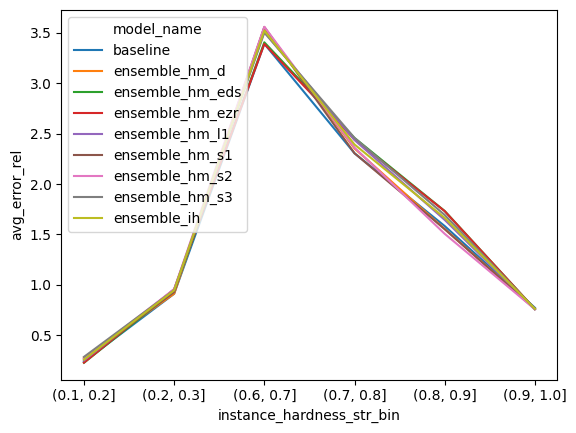

In [107]:

liver_test_predictions = process_prediction_results(model_results=liver_results, dataset_name='liver') 
concatenated_df = process_predictions(liver_test_predictions, all_meta_features_test_dict['liver'])
avg_residual_per_ih = calculate_avg_residual_per_ih(concatenated_df)
plot_avg_residual_per_ih(avg_residual_per_ih)

## real_estate

In [164]:
real_estate_results = run_experiment_with_timeout(
    'real_estate', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing real_estate - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [166]:
real_estate_results_df = get_df_results(real_estate_results)
real_estate_agg_results = get_agg_results(real_estate_results_df)
real_estate_agg_results

mse               r2             mae            rmse  \
                    mean      std    mean     std    mean     std    mean   
model_name                                                                  
baseline         45.3153  17.5081  0.7359  0.0925  4.6971  0.9423  6.6133   
ensemble_hm_d    48.0232  20.5969  0.7166  0.1257  4.6331  1.0962  6.7679   
ensemble_hm_eds  46.1335  16.1153  0.7305  0.0855  4.8028  0.8073  6.7030   
ensemble_hm_ezr  45.6040  20.2320  0.7341  0.1087  4.7314  1.0754  6.5995   
ensemble_hm_l1   49.1103  19.4265  0.7106  0.1174  4.7079  1.0687  6.8724   
ensemble_hm_s1   48.3658  19.9065  0.7147  0.1212  4.6674  1.0407  6.8069   
ensemble_hm_s2   49.0648  21.9127  0.7097  0.1371  4.6475  1.1114  6.8287   
ensemble_hm_s3   47.3114  15.1650  0.7238  0.0786  4.8349  0.8733  6.8019   
ensemble_ih      48.4538  19.5386  0.7143  0.1188  4.7214  0.9999  6.8230   
linear_reg       62.6112  14.9619  0.6338  0.0737  5.7106  0.6940  7.8720   

                           mape         execution_time                   
                    std    mean     std           mean     std      sum  
model_name                                                               
baseline         1.4050  0.1387  0.0389         3.1507  0.0628  15.7534  
ensemble_hm_d    1.6652  0.1359  0.0425         2.8478  0.0299  14.2389  
ensemble_hm_eds  1.2262  0.1403  0.0359         2.8653  0.0565  14.3264  
ensemble_hm_ezr  1.6011  0.1391  0.0426         2.8440  0.0389  14.2198  
ensemble_hm_l1   1.5333  0.1375  0.0424         2.8509  0.0365  14.2544  
ensemble_hm_s1   1.5939  0.1371  0.0417         3.0202  0.3011  15.1012  
ensemble_hm_s2   1.7441  0.1359  0.0427         2.8411  0.0321  14.2056  
ensemble_hm_s3   1.1436  0.1413  0.0369         2.8701  0.0705  14.3506  
ensemble_ih      1.5413  0.1381  0.0395         4.6227  0.2542  23.1135  
linear_reg       0.8964  0.1758  0.0319         0.0006  0.0001   0.0032

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_3078/2918698116.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


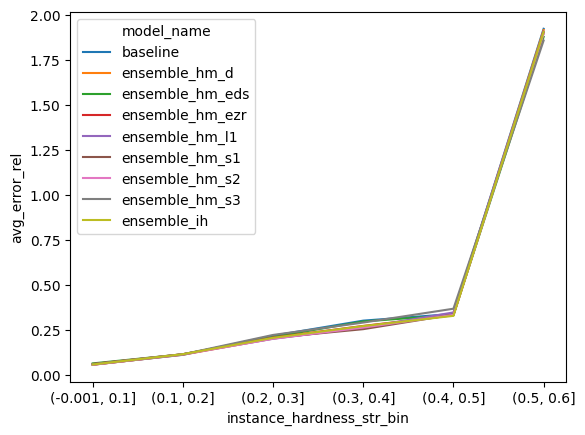

In [110]:
real_estate_test_predictions = \
    process_prediction_results(model_results=real_estate_results, dataset_name='real_estate') 
concatenated_df = process_predictions(real_estate_test_predictions, all_meta_features_test_dict['real_estate'])
avg_residual_per_ih = calculate_avg_residual_per_ih(concatenated_df)
plot_avg_residual_per_ih(avg_residual_per_ih)

## machineCPU

In [155]:
machineCPU_results = run_experiment_with_timeout(
    'machineCPU', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing machineCPU - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [248]:
machineCPU_results_df = get_df_results(machineCPU_results)
machineCPU_agg_results = get_agg_results(machineCPU_results_df)
machineCPU_agg_results

mse                 r2              mae          \
                      mean        std    mean     std     mean     std   
model_name                                                               
baseline         3396.8046  2725.4175  0.8790  0.0547  28.7158  7.1063   
ensemble_hm_d    3434.3710  2640.9749  0.8804  0.0475  29.4652  6.8838   
ensemble_hm_eds  3717.5594  2833.8270  0.8695  0.0541  30.1958  7.3053   
ensemble_hm_ezr  4045.0431  2988.8888  0.8576  0.0598  30.8757  7.6506   
ensemble_hm_l1   3373.6312  2508.5544  0.8799  0.0450  29.3131  6.5675   
ensemble_hm_s1   3564.3002  2787.9305  0.8738  0.0522  29.8589  6.7156   
ensemble_hm_s2   3287.1097  2471.4931  0.8836  0.0439  28.7707  6.5873   
ensemble_hm_s3   3969.7087  2853.5069  0.8601  0.0604  30.0416  7.2920   
ensemble_ih      3420.6021  2713.1825  0.8811  0.0506  29.1883  6.9643   
linear_reg       4320.9630  2485.3003  0.8274  0.0759  40.0855  6.4918   

                    rmse             mape         execution_time          \
                    mean      std    mean     std           mean     std   
model_name                                                                 
baseline         54.5657  22.8962  0.3684  0.0243         2.9944  3.2498   
ensemble_hm_d    55.0059  22.6031  0.3886  0.0299         1.4631  0.0340   
ensemble_hm_eds  57.2937  23.3184  0.3989  0.0310         1.4700  0.0406   
ensemble_hm_ezr  59.7607  24.3337  0.3994  0.0499         1.4655  0.0432   
ensemble_hm_l1   54.8111  21.4876  0.3912  0.0233         1.4766  0.0376   
ensemble_hm_s1   56.1091  22.8055  0.3848  0.0500         1.4544  0.0258   
ensemble_hm_s2   54.0388  21.4159  0.3668  0.0366         1.4702  0.0261   
ensemble_hm_s3   59.0449  24.5817  0.3992  0.0220         1.4757  0.0197   
ensemble_ih      54.7425  23.0178  0.3877  0.0206         2.6041  0.0462   
linear_reg       63.3809  19.4878  0.7654  0.0394         0.0006  0.0001   

                          
                     sum  
model_name                
baseline         14.9718  
ensemble_hm_d     7.3154  
ensemble_hm_eds   7.3500  
ensemble_hm_ezr   7.3274  
ensemble_hm_l1    7.3828  
ensemble_hm_s1    7.2718  
ensemble_hm_s2    7.3510  
ensemble_hm_s3    7.3784  
ensemble_ih      13.0205  
linear_reg        0.0032

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_3078/2918698116.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


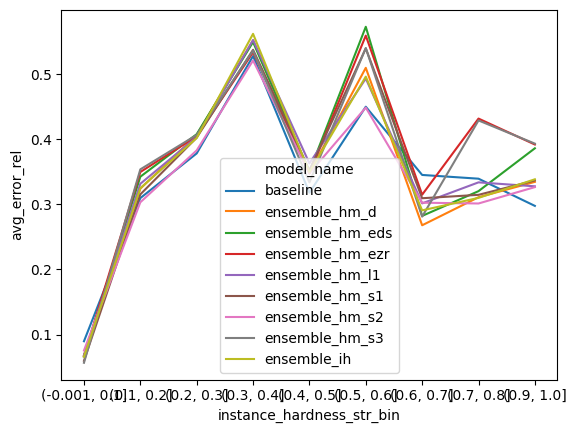

In [113]:
machineCPU_test_predictions = \
    process_prediction_results(model_results=machineCPU_results, dataset_name='machineCPU') 
concatenated_df = process_predictions(machineCPU_test_predictions, all_meta_features_test_dict['machineCPU'])
avg_residual_per_ih = calculate_avg_residual_per_ih(concatenated_df)
plot_avg_residual_per_ih(avg_residual_per_ih)

## abalone (1h p/ rodar)

In [114]:
linear_reg = linear_model.LinearRegression()
challenger_experiments_without_ih = {
    'ensemble_hm_s2': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "S2",
            "hardness_measures_list": ["S2"]
        }
    },
    'ensemble_hm_s1': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "S1",
            "hardness_measures_list": ["S1"]
        }
    },
    'ensemble_hm_s3': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "S3",
            "hardness_measures_list": ["S3"]
        }
    },
    'ensemble_hm_d': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "D",
            "hardness_measures_list": ["D"]
        }
    },
    'ensemble_hm_l1': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "L1",
            "hardness_measures_list": ["L1"]
        }
    },
    'ensemble_hm_ezr': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "EZR",
            "hardness_measures_list": ["EZR"]
        }
    },
    'ensemble_hm_eds': {
        "model": ensemble_hm,
        "params": {
            "include_hardness_measures": True,
            "include_instance_hardness": False,
            "meta_feature": "EDS",
            "hardness_measures_list": ["EDS"]
        }
    },
    'linear_reg': {
        "model": linear_reg,
    }
}

In [172]:
abalone_results = run_experiment_with_timeout(
    'abalone', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing abalone - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [173]:
abalone_results_df = get_df_results(abalone_results)
abalone_agg_results = get_agg_results(abalone_results_df)
abalone_agg_results

mse              r2             mae            rmse  \
                   mean     std    mean     std    mean     std    mean   
model_name                                                                
baseline         4.7228  0.4447  0.5454  0.0087  1.5065  0.0563  2.1713   
ensemble_hm_d    4.7045  0.3892  0.5469  0.0049  1.5120  0.0534  2.1675   
ensemble_hm_eds  4.7561  0.5100  0.5426  0.0103  1.5153  0.0648  2.1784   
ensemble_hm_ezr  4.7421  0.3833  0.5432  0.0081  1.5165  0.0441  2.1762   
ensemble_hm_l1   4.7390  0.4037  0.5436  0.0060  1.5171  0.0578  2.1754   
ensemble_hm_s1   4.6811  0.4423  0.5495  0.0058  1.5101  0.0612  2.1617   
ensemble_hm_s2   4.6967  0.4049  0.5477  0.0047  1.5110  0.0544  2.1656   
ensemble_hm_s3   4.7812  0.4683  0.5399  0.0081  1.5250  0.0678  2.1845   
ensemble_ih      4.7264  0.4203  0.5449  0.0050  1.5136  0.0582  2.1723   
linear_reg       4.9423  0.4954  0.5240  0.0263  1.5920  0.0573  2.2209   

                           mape         execution_time                    
                    std    mean     std           mean     std       sum  
model_name                                                                
baseline         0.1018  0.1479  0.0040        54.6142  0.9089  273.0712  
ensemble_hm_d    0.0892  0.1491  0.0044        56.4263  0.5431  282.1313  
ensemble_hm_eds  0.1159  0.1493  0.0049        55.6887  1.3048  278.4434  
ensemble_hm_ezr  0.0877  0.1496  0.0031        55.2770  1.0801  276.3851  
ensemble_hm_l1   0.0923  0.1495  0.0047        55.6146  1.2779  278.0728  
ensemble_hm_s1   0.1013  0.1488  0.0050        55.7857  0.6457  278.9287  
ensemble_hm_s2   0.0928  0.1490  0.0045        55.7568  1.1811  278.7842  
ensemble_hm_s3   0.1064  0.1501  0.0053        56.1645  1.0299  280.8223  
ensemble_ih      0.0961  0.1492  0.0047        64.5028  1.9385  322.5138  
linear_reg       0.1107  0.1605  0.0044         0.0012  0.0003    0.0060

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_31761/2918698116.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


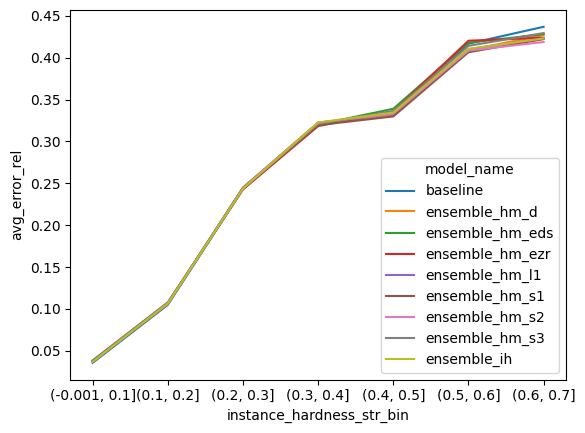

In [41]:
abalone_test_predictions = \
    process_prediction_results(model_results=abalone_results, dataset_name='abalone') 
concatenated_df = process_predictions(
    abalone_test_predictions, 
    all_meta_features_test_dict['abalone']
)
avg_residual_per_ih = calculate_avg_residual_per_ih(concatenated_df)
plot_avg_residual_per_ih(avg_residual_per_ih)

## wine_white (1h p/ rodar)

In [176]:
wine_quality_white_results = run_experiment_with_timeout(
    'wine_quality_white', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)


========== Processing wine_quality_white - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [177]:
wine_quality_white_results_df = get_df_results(wine_quality_white_results)
wine_quality_white_agg_results = get_agg_results(wine_quality_white_results_df)
wine_quality_white_agg_results

mse              r2             mae            rmse  \
                   mean     std    mean     std    mean     std    mean   
model_name                                                                
baseline         0.4586  0.0108  0.4152  0.0137  0.5018  0.0077  0.6771   
ensemble_hm_d    0.4407  0.0111  0.4380  0.0141  0.4952  0.0065  0.6638   
ensemble_hm_eds  0.4380  0.0106  0.4414  0.0135  0.4929  0.0075  0.6618   
ensemble_hm_ezr  0.4456  0.0116  0.4318  0.0150  0.4996  0.0064  0.6675   
ensemble_hm_l1   0.4347  0.0117  0.4456  0.0149  0.4905  0.0081  0.6593   
ensemble_hm_s1   0.4316  0.0136  0.4496  0.0175  0.4884  0.0075  0.6569   
ensemble_hm_s2   0.4300  0.0130  0.4517  0.0167  0.4864  0.0076  0.6557   
ensemble_hm_s3   0.4439  0.0123  0.4340  0.0153  0.4961  0.0095  0.6662   
ensemble_ih      0.4317  0.0124  0.4494  0.0158  0.4874  0.0075  0.6570   
linear_reg       0.5681  0.0182  0.2756  0.0237  0.5853  0.0078  0.7536   

                           mape         execution_time                    
                    std    mean     std           mean     std       sum  
model_name                                                                
baseline         0.0080  0.0898  0.0013        72.5016  2.2425  362.5080  
ensemble_hm_d    0.0084  0.0885  0.0011        73.6820  0.8732  368.4098  
ensemble_hm_eds  0.0080  0.0881  0.0011        73.6820  1.0881  368.4100  
ensemble_hm_ezr  0.0088  0.0892  0.0010        73.3206  0.9907  366.6029  
ensemble_hm_l1   0.0089  0.0876  0.0013        73.3320  0.7881  366.6598  
ensemble_hm_s1   0.0104  0.0873  0.0013        72.6051  1.3613  363.0257  
ensemble_hm_s2   0.0100  0.0869  0.0013        73.4123  1.3029  367.0617  
ensemble_hm_s3   0.0092  0.0887  0.0015        73.9757  0.7674  369.8786  
ensemble_ih      0.0094  0.0871  0.0012        84.7584  1.2605  423.7920  
linear_reg       0.0120  0.1033  0.0014         0.0137  0.0023    0.0684

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_31761/2918698116.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


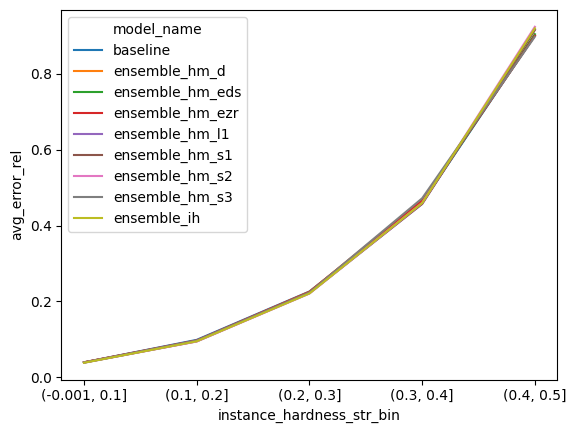

In [44]:
wine_quality_white_test_predictions = \
    process_prediction_results(model_results=wine_quality_white_results, dataset_name='wine_quality_white') 
concatenated_df = process_predictions(
    wine_quality_white_test_predictions, 
    all_meta_features_test_dict['wine_quality_white']
)
avg_residual_per_ih = calculate_avg_residual_per_ih(concatenated_df)
plot_avg_residual_per_ih(avg_residual_per_ih)

## wine_red

In [180]:
wine_quality_red_results = run_experiment_with_timeout(
    'wine_quality_red', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)


========== Processing wine_quality_red - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [181]:
wine_quality_red_results_df = get_df_results(wine_quality_red_results)
wine_quality_red_agg_results = get_agg_results(wine_quality_red_results_df)
wine_quality_red_agg_results

mse              r2             mae            rmse  \
                   mean     std    mean     std    mean     std    mean   
model_name                                                                
baseline         0.3952  0.0129  0.3936  0.0211  0.4695  0.0097  0.6286   
ensemble_hm_d    0.3734  0.0153  0.4270  0.0258  0.4537  0.0068  0.6109   
ensemble_hm_eds  0.3758  0.0157  0.4232  0.0284  0.4550  0.0104  0.6129   
ensemble_hm_ezr  0.3727  0.0189  0.4281  0.0287  0.4557  0.0128  0.6103   
ensemble_hm_l1   0.3739  0.0125  0.4260  0.0242  0.4543  0.0069  0.6114   
ensemble_hm_s1   0.3701  0.0157  0.4320  0.0259  0.4516  0.0085  0.6082   
ensemble_hm_s2   0.3697  0.0146  0.4326  0.0248  0.4503  0.0067  0.6080   
ensemble_hm_s3   0.3817  0.0193  0.4143  0.0296  0.4610  0.0119  0.6176   
ensemble_ih      0.3715  0.0146  0.4299  0.0244  0.4515  0.0074  0.6094   
linear_reg       0.4234  0.0282  0.3498  0.0504  0.5037  0.0241  0.6504   

                           mape         execution_time                   
                    std    mean     std           mean     std      sum  
model_name                                                               
baseline         0.0103  0.0865  0.0016        15.4491  2.2150  77.2454  
ensemble_hm_d    0.0125  0.0835  0.0012        13.4070  0.2073  67.0348  
ensemble_hm_eds  0.0128  0.0837  0.0017        13.5197  0.3498  67.5987  
ensemble_hm_ezr  0.0155  0.0839  0.0021        13.6746  0.4546  68.3728  
ensemble_hm_l1   0.0102  0.0835  0.0011        13.4429  0.2268  67.2147  
ensemble_hm_s1   0.0129  0.0832  0.0015        13.3543  0.2379  66.7714  
ensemble_hm_s2   0.0120  0.0829  0.0010        13.3628  0.1567  66.8138  
ensemble_hm_s3   0.0156  0.0849  0.0018        13.3808  0.1315  66.9040  
ensemble_ih      0.0120  0.0831  0.0011        19.7855  0.4426  98.9277  
linear_reg       0.0219  0.0923  0.0043         0.0008  0.0002   0.0040

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_39339/2918698116.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_residual_per_ih = concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


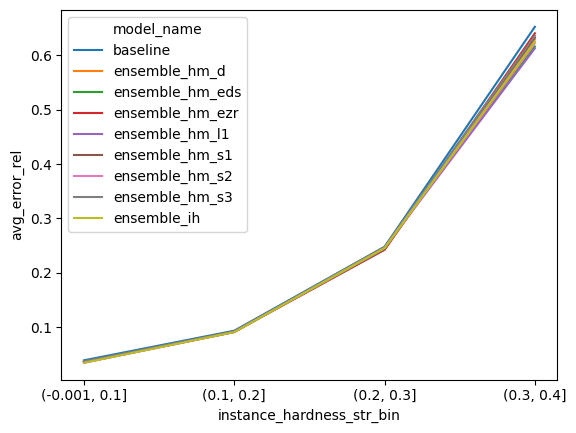

In [182]:
wine_quality_red_test_predictions = \
    process_prediction_results(model_results=wine_quality_red_results, dataset_name='wine_quality_red') 
concatenated_df = process_predictions(
    wine_quality_red_test_predictions, 
    all_meta_features_test_dict['wine_quality_red']
)
avg_residual_per_ih = calculate_avg_residual_per_ih(concatenated_df)
plot_avg_residual_per_ih(avg_residual_per_ih)

## concrete

In [184]:
concrete_results = run_experiment_with_timeout(
    'concrete', 
    baseline_model=ensemble, 
    challenger_experiments=challenger_experiments
)

========== Processing concrete - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: ensemble_ih...


/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/Users/victor.nunes/Documents/Github/regression-instance-hardness/.venv/lib/python3.9/site-packages/sklearn/svm/_classes.py:

Running challenger model: ensemble_hm_s2...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1', 'S2', 'S3', 'D', 'L1', 'EZR', 'EDS']


Running challenger model: ensemble_hm_eds...
Running challenger model: linear_reg...


In [185]:
concrete_results_df = get_df_results(concrete_results)
concrete_agg_results = get_agg_results(concrete_results_df)
concrete_agg_results

mse               r2             mae             rmse  \
                     mean      std    mean     std    mean     std     mean   
model_name                                                                    
baseline          47.4462   8.1882  0.8284  0.0332  5.2210  0.3992   6.8678   
ensemble_hm_d     37.1343   7.8344  0.8660  0.0296  4.6069  0.4318   6.0655   
ensemble_hm_eds   40.3917   6.4121  0.8539  0.0264  4.8223  0.3227   6.3388   
ensemble_hm_ezr   40.8656   6.7221  0.8524  0.0253  4.8619  0.4136   6.3750   
ensemble_hm_l1    39.3300   8.5271  0.8579  0.0332  4.7019  0.4440   6.2400   
ensemble_hm_s1    39.6904   7.1861  0.8568  0.0270  4.7870  0.4393   6.2790   
ensemble_hm_s2    37.2974   7.8527  0.8654  0.0297  4.6201  0.4334   6.0785   
ensemble_hm_s3    43.4431   8.0858  0.8432  0.0307  4.9635  0.4369   6.5666   
ensemble_ih       38.7221   7.9855  0.8602  0.0307  4.6983  0.4025   6.1944   
linear_reg       109.5027  10.5288  0.6019  0.0655  8.2842  0.4562  10.4552   

                           mape         execution_time                   
                    std    mean     std           mean     std      sum  
model_name                                                               
baseline         0.5913  0.2048  0.0298         8.9902  0.4778  44.9508  
ensemble_hm_d    0.6554  0.1781  0.0246         7.9028  0.1833  39.5139  
ensemble_hm_eds  0.5142  0.1847  0.0230         8.0437  0.4001  40.2183  
ensemble_hm_ezr  0.5304  0.1918  0.0386         8.3549  0.9939  41.7744  
ensemble_hm_l1   0.7009  0.1815  0.0240         7.9615  0.2122  39.8076  
ensemble_hm_s1   0.5754  0.1839  0.0250         7.8392  0.2340  39.1961  
ensemble_hm_s2   0.6604  0.1777  0.0229         7.8502  0.2131  39.2508  
ensemble_hm_s3   0.6350  0.1961  0.0293         7.9242  0.2358  39.6208  
ensemble_ih      0.6623  0.1802  0.0234        13.7628  0.7443  68.8142  
linear_reg       0.4897  0.3160  0.0326         0.0007  0.0001   0.0035

In [50]:
concrete_test_predictions = pd.DataFrame()
for part in concrete_results:
    for model in concrete_results[part].keys():
        new_df = pd.DataFrame(concrete_results[part][model])\
            [['y_pred', 'y_true']]\
            .assign(dataset="concrete")\
            .assign(model_name=model)\
            .assign(partition=part)
        concrete_test_predictions = pd.concat([
            concrete_test_predictions, 
            new_df
        ], ignore_index=True)

In [51]:
list_df = list()
for model in concrete_test_predictions['model_name'].unique():
    model_df = concrete_test_predictions.query("model_name == @model").reset_index(drop=True)
    # Concatenate horizontally (axis=1) instead of vertically
    tmp_df = pd.concat([
        model_df, 
        all_meta_features_test_dict['yacht']['instance_hardness'][['instance_hardness']],
        all_meta_features_test_dict['yacht']['hardness_measures'],
    ], axis=1)  # Changed from axis=0 to axis=1
    list_df.append(tmp_df)
concatenated_df = pd.concat(list_df, ignore_index=True)
concatenated_df['error_abs'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred'])
concatenated_df['error_rel'] = np.abs(concatenated_df['y_true'] - concatenated_df['y_pred']) / concatenated_df['y_true']
concatenated_df['error_rel_sq'] = \
    (concatenated_df['y_true'] - concatenated_df['y_pred']) ** 2 / concatenated_df['y_true'] ** 2
concatenated_df['instance_hardness_bin'] = pd.cut(
    concatenated_df['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    include_lowest=True
)

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_31761/3168568460.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\


<Axes: xlabel='instance_hardness_str_bin', ylabel='avg_error_rel'>

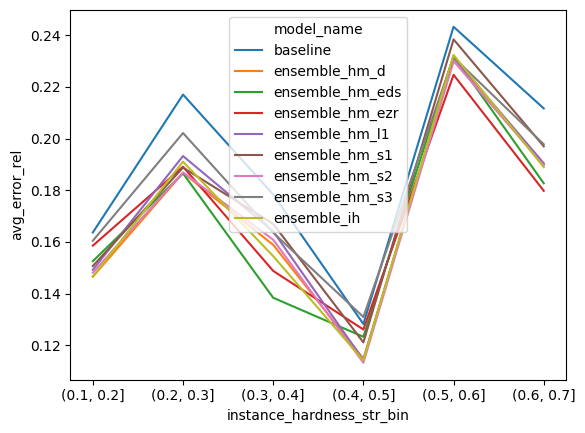

In [52]:
avg_residual_per_ih = \
    concatenated_df.groupby(by=['model_name', 'instance_hardness_bin'])\
    .agg(
        avg_error_rel = ("error_rel", "mean"),
        std_error_rel = ("error_rel", "std")
    )\
    .reset_index()\
    .dropna()\
    .assign(instance_hardness_str_bin = lambda x: x['instance_hardness_bin'].astype(str))


sns.lineplot(
    data=avg_residual_per_ih.query("model_name != 'linear_reg'"),
    x='instance_hardness_str_bin',
    y='avg_error_rel',
    hue='model_name'
)


## All results

In [ ]:
## Load all dataset results

yatch_results_df

In [5]:
all_results = pd.concat([
    yatch_results_df.assign(dataset='yacht'),
    student_marks_results_df.assign(dataset='student_marks'),
    liver_results_df.assign(dataset='liver'),
    real_estate_results_df.assign(dataset='real_estate'),
    machineCPU_results_df.assign(dataset='machine_cpu'),
    abalone_results_df.assign(dataset='abalone'),
    wine_quality_white_results_df.assign(dataset='wine_quality_white'),
    wine_quality_red_results_df.assign(dataset='wine_quality_red'),
    concrete_results_df.assign(dataset='concrete'),
], ignore_index=True)

agg_partitions_results = \
    all_results.groupby(['dataset', 'model_name']).agg({
        'mse': ['mean', 'std'],
        'r2': ['mean', 'std'],
        'mae': ['mean', 'std'],
        'rmse': ['mean', 'std'],
        'mape': ['mean', 'std'],
        'execution_time': ['mean', 'std', 'sum']
    }).round(4)

NameError: name 'yatch_results_df' is not defined

In [328]:
ensemble_latex_names = {
    "baseline": r"$DES$",
    "ensemble_hm_d": r"$DES_{Degree_{IHM}}$",
    "ensemble_hm_eds": r"$DES_{EDS}$",
    "ensemble_hm_ezr": r"$DES_{EZR}$",
    "ensemble_hm_l1": r"$DES_{LE}$",
    "ensemble_hm_s1": r"$DES_{S1}$",
    "ensemble_hm_s2": r"$DES_{S2}$",
    "ensemble_hm_s3": r"$DES_{S3}$",
    "ensemble_ih": r"$DES_{IH}$",
}

### DES MSE for all dataset

In [359]:
agg_partitions_results\
    [[("mse", "mean")]]\
    .droplevel(1, axis=1)\
    .pivot_table(
        index="model_name",
        columns="dataset",
        values="mse"
    )\
    .rename(index=ensemble_latex_names)\
    .query("model_name != 'linear_reg'")\
    .round(3)\
    .T\
    # .to_latex(
    #     caption="MSE obtained for all models trained",
    #     label="tab:mse_all_models",
    #     escape=False,
    #     float_format="%.3f"
    # )

model_name,$DES$,$DES_{Degree_{IHM}}$,$DES_{EDS}$,$DES_{EZR}$,$DES_{LE}$,$DES_{S1}$,$DES_{S2}$,$DES_{S3}$,$DES_{IH}$
dataset,,,,,,,,,
abalone,4.723,4.704,4.756,4.742,4.739,4.681,4.697,4.781,4.726
concrete,47.446,37.134,40.392,40.866,39.330,39.690,37.297,43.443,38.722
liver,12.369,12.549,12.719,12.731,12.792,12.549,12.597,12.839,12.796
machine_cpu,3396.805,3434.371,3717.559,4045.043,3373.631,3564.300,3287.110,3969.709,3420.602
real_estate,45.315,48.023,46.134,45.604,49.110,48.366,49.065,47.311,48.454
student_marks,2.348,1.790,1.970,2.011,1.828,1.853,1.774,2.112,1.812
wine_quality_red,0.395,0.373,0.376,0.373,0.374,0.370,0.370,0.382,0.372
wine_quality_white,0.459,0.441,0.438,0.446,0.435,0.432,0.430,0.444,0.432
yacht,40.713,26.437,28.559,37.647,26.650,28.081,26.478,37.879,27.462


Generate compilation of meta-feature for each dataset

In [191]:
yacht_all_data = compile_data_and_meta_data(
    predictions_df=yatch_results_df, 
    ih_data=all_meta_features_test_dict['yacht']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['yacht']['hardness_measures']
)

student_marks_all_data = compile_data_and_meta_data(
    predictions_df=student_marks_results_df, 
    ih_data=all_meta_features_test_dict['student_marks']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['student_marks']['hardness_measures']
)

liver_all_data = compile_data_and_meta_data(
    predictions_df=liver_results_df, 
    ih_data=all_meta_features_test_dict['liver']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['liver']['hardness_measures']
)

real_estate_all_data = compile_data_and_meta_data(
    predictions_df=real_estate_results_df, 
    ih_data=all_meta_features_test_dict['real_estate']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['real_estate']['hardness_measures']
)

machineCPU_all_data = compile_data_and_meta_data(
    predictions_df=machineCPU_results_df, 
    ih_data=all_meta_features_test_dict['machineCPU']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['machineCPU']['hardness_measures']
)

abalone_all_data = compile_data_and_meta_data(
    predictions_df=abalone_results_df, 
    ih_data=all_meta_features_test_dict['abalone']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['abalone']['hardness_measures']
)

wine_quality_white_all_data = compile_data_and_meta_data(
    predictions_df=wine_quality_white_results_df, 
    ih_data=all_meta_features_test_dict['wine_quality_white']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['wine_quality_white']['hardness_measures']
)

wine_quality_red_all_data = compile_data_and_meta_data(
    predictions_df=wine_quality_red_results_df, 
    ih_data=all_meta_features_test_dict['wine_quality_red']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['wine_quality_red']['hardness_measures']
)

concrete_all_data = compile_data_and_meta_data(
    predictions_df=concrete_results_df, 
    ih_data=all_meta_features_test_dict['concrete']['instance_hardness'][['instance_hardness']], 
    hm_data=all_meta_features_test_dict['concrete']['hardness_measures']
)

In [194]:
all_dataset_all_data = pd.concat([
    yacht_all_data.assign(dataset_name="yacht"),
    student_marks_all_data.assign(dataset_name="student_marks"),
    liver_all_data.assign(dataset_name="liver"),
    real_estate_all_data.assign(dataset_name="real_estate"),
    machineCPU_all_data.assign(dataset_name="machine_cpu"),
    abalone_all_data.assign(dataset_name="abalone"),
    wine_quality_white_all_data.assign(dataset_name="wine_quality_white"),
    wine_quality_red_all_data.assign(dataset_name="wine_quality_red"),
    concrete_all_data.assign(dataset_name="concrete"),
    ], ignore_index=True)
all_dataset_all_data.shape

(130810, 42)

In [195]:

# all_dataset_all_data['baseline_residual'] = \
#     (all_dataset_all_data['baseline_prediction'] - all_dataset_all_data['y_pred'])/all_dataset_all_data['baseline_prediction']
# all_dataset_all_data['target_residual'] = \
#     (all_dataset_all_data['y_true'] - all_dataset_all_data['y_pred'])/all_dataset_all_data['y_true']
# ih_bucket_labels = ['0-0.1', '0.1-0.2', '0.2-0.3', '0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7-0.8', '0.8-0.9', '0.9-1.0']

all_dataset_all_data['instance_hardness_bin'] = pd.cut(
    all_dataset_all_data['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    labels=ih_bucket_labels, 
    include_lowest=True
).astype("str")

# residual_buckets_labels = ['[-inf, -1]', '[-1, -0.5]', '[-0.5, 0]', '[0, 0.5]', '[0.5, 1]', '[1, inf]']
# all_dataset_all_data['target_residual_bin'] = pd.cut(
#     all_dataset_all_data['target_residual'], 
#     bins=[-np.inf, -1, -0.5, 0, 0.5, 1.0, np.inf], 
#     labels=residual_buckets_labels, 
#     include_lowest=True
# ).astype("str")

all_dataset_all_data['squared_error'] = (all_dataset_all_data['y_true'] - all_dataset_all_data['y_pred']) ** 2
all_dataset_all_data.head()

,mse,r2,mae,rmse,mape,execution_time,y_pred,y_true,status,model_name,partition,baseline_prediction,baseline_true,instance_hardness,V0,V1,V2,V3,V4,V5,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U,dataset_name,V6,V7,V8,V9,V10,instance_hardness_bin,squared_error
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.296429,0.11,success,baseline,1,1.296429,0.11,0.336416,-2.3,0.568,4.78,3.99,3.17,0.125,0.11,1.000000,0.993192,0.882736,0.548223,0.113025,0.013070,0.0,0.480519,0.382074,0,0.098165,0.619947,1.897346e-03,0.75,0.823529,yacht,NaN,NaN,NaN,NaN,NaN,0.3-0.4,1.407613
1,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.259244,0.27,success,baseline,1,1.259244,0.27,0.246059,-2.3,0.568,4.78,3.99,3.17,0.150,0.27,1.000000,0.993029,0.863192,0.548223,0.103010,0.011701,0.0,0.480519,0.299684,0,0.012821,0.701633,1.091123e-03,0.75,0.941176,yacht,NaN,NaN,NaN,NaN,NaN,0.2-0.3,0.978603
2,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.481672,0.47,success,baseline,1,1.481672,0.47,0.115157,-2.3,0.568,4.78,3.99,3.17,0.175,0.47,1.000000,0.992859,0.843648,0.548223,0.091037,0.010095,0.0,0.480519,0.193667,0,0.012821,0.677125,3.946838e-04,0.75,0.764706,yacht,NaN,NaN,NaN,NaN,NaN,0.1-0.2,1.02348
3,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,1.726464,0.78,success,baseline,1,1.726464,0.78,0.084610,-2.3,0.568,4.78,3.99,3.17,0.200,0.78,0.857143,0.992741,0.830619,0.548223,0.073742,0.007836,0.0,0.480519,0.056340,0,0.012821,0.666275,3.012436e-07,0.75,0.941176,yacht,NaN,NaN,NaN,NaN,NaN,0-0.1,0.895793
4,32.184393,0.83783,3.231343,5.673129,2.461356,2.331067,2.043427,1.18,success,baseline,1,2.043427,1.18,0.100300,-2.3,0.568,4.78,3.99,3.17,0.225,1.18,1.000000,0.992649,0.820847,0.548223,0.053839,0.005339,0.0,0.480519,0.103001,0,0.012821,0.683648,1.508886e-03,0.75,0.705882,yacht,NaN,NaN,NaN,NaN,NaN,0.1-0.2,0.745506


In [207]:
stats_per_ih = \
    all_dataset_all_data.groupby(by=['dataset_name', 'model_name', 'instance_hardness_bin'])\
    .agg(
        # avg_baseline_residual = ("baseline_residual", "mean"),
        # std_baseline_residual = ("baseline_residual", "std"),
        avg_y_true = ("y_true", "mean"),
        count = ("y_true", "count"),
        # avg_target_residual = ("target_residual", "mean"),
        # std_target_residual = ("target_residual", "std"),
        avg_squared_error = ("squared_error", "mean"),
    )\
    .reset_index()\
    .dropna()

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_39339/3360160579.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_plot = stats_per_ih\


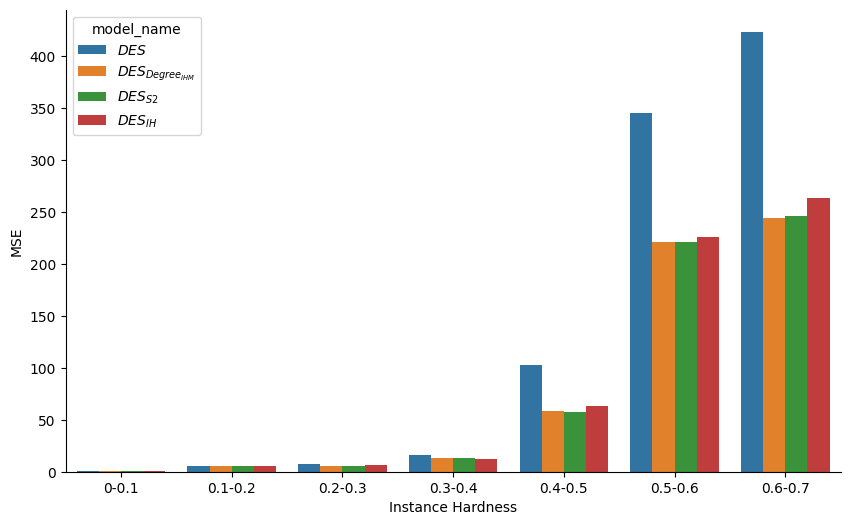

In [330]:
models_to_plot = [
    "baseline",
    "ensemble_hm_d",
    # "ensemble_hm_l1",
    # "ensemble_hm_s1",
    "ensemble_hm_s2",
    "ensemble_ih",
]

df_plot = stats_per_ih\
    .query("model_name in @models_to_plot and dataset_name == 'yacht'")\
    .replace(ensemble_latex_names)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=df_plot,
    x='instance_hardness_bin',
    y='avg_squared_error',
    hue='model_name',
)

_ = plt.ylabel("MSE")
_ = plt.xlabel("Instance Hardness")
fig.savefig(fname='img/yacht-mse-per-model.png', dpi=300, format='png', bbox_inches='tight')
sns.despine()

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_39339/2816197999.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_plot = stats_per_ih\


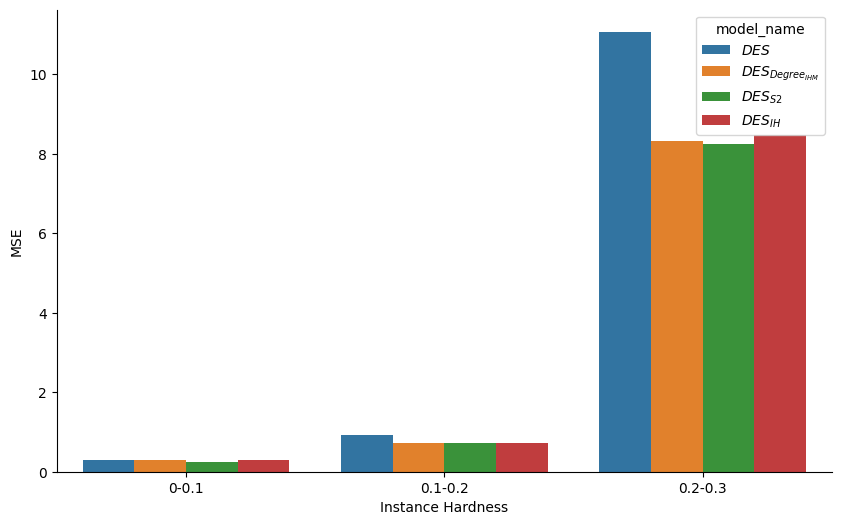

In [363]:
models_to_plot = [
    "baseline",
    "ensemble_hm_d",
    # "ensemble_hm_l1",
    # "ensemble_hm_s1",
    "ensemble_hm_s2",
    "ensemble_ih",
]
df_plot = stats_per_ih\
    .query("model_name in @models_to_plot and dataset_name == 'student_marks'")\
    .replace(ensemble_latex_names)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=df_plot,
    x='instance_hardness_bin',
    y='avg_squared_error',
    hue='model_name',
)

_ = plt.ylabel("MSE")
_ = plt.xlabel("Instance Hardness")
fig.savefig(fname='img/student-marks-mse-per-model.png', dpi=300, format='png', bbox_inches='tight')
sns.despine()

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_39339/890214604.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_plot = stats_per_ih\


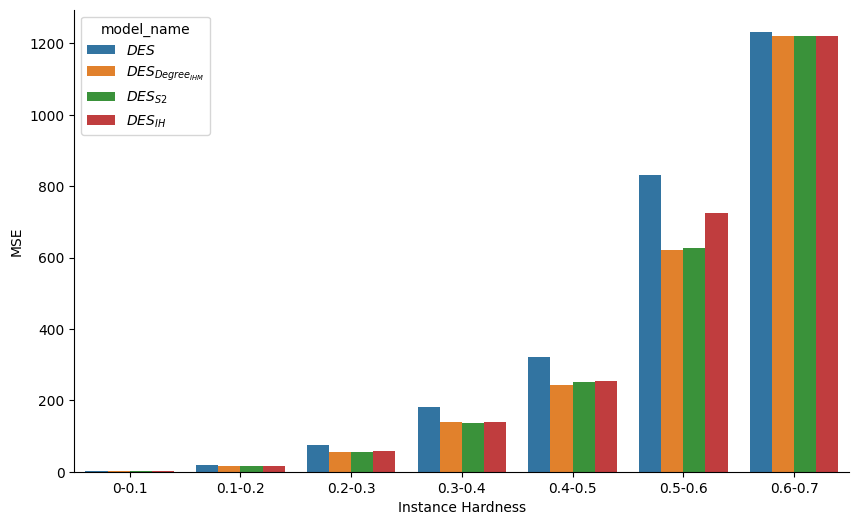

In [364]:
models_to_plot = [
    "baseline",
    "ensemble_hm_d",
    # "ensemble_hm_l1",
    # "ensemble_hm_s1",
    "ensemble_hm_s2",
    "ensemble_ih",
]
df_plot = stats_per_ih\
    .query("model_name in @models_to_plot and dataset_name == 'concrete'")\
    .replace(ensemble_latex_names)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=df_plot,
    x='instance_hardness_bin',
    y='avg_squared_error',
    hue='model_name',
)

_ = plt.ylabel("MSE")
_ = plt.xlabel("Instance Hardness")
fig.savefig(fname='img/concrete-mse-per-model.png', dpi=300, format='png', bbox_inches='tight')
sns.despine()

In [358]:
all_dataset_all_data\
    .query("dataset_name == 'real_estate' and model_name == 'baseline'")\
    [['mse', "squared_error"]].mean()

mse              45.315326
squared_error    45.315326
dtype: object

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_39339/2136886114.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_plot = stats_per_ih\


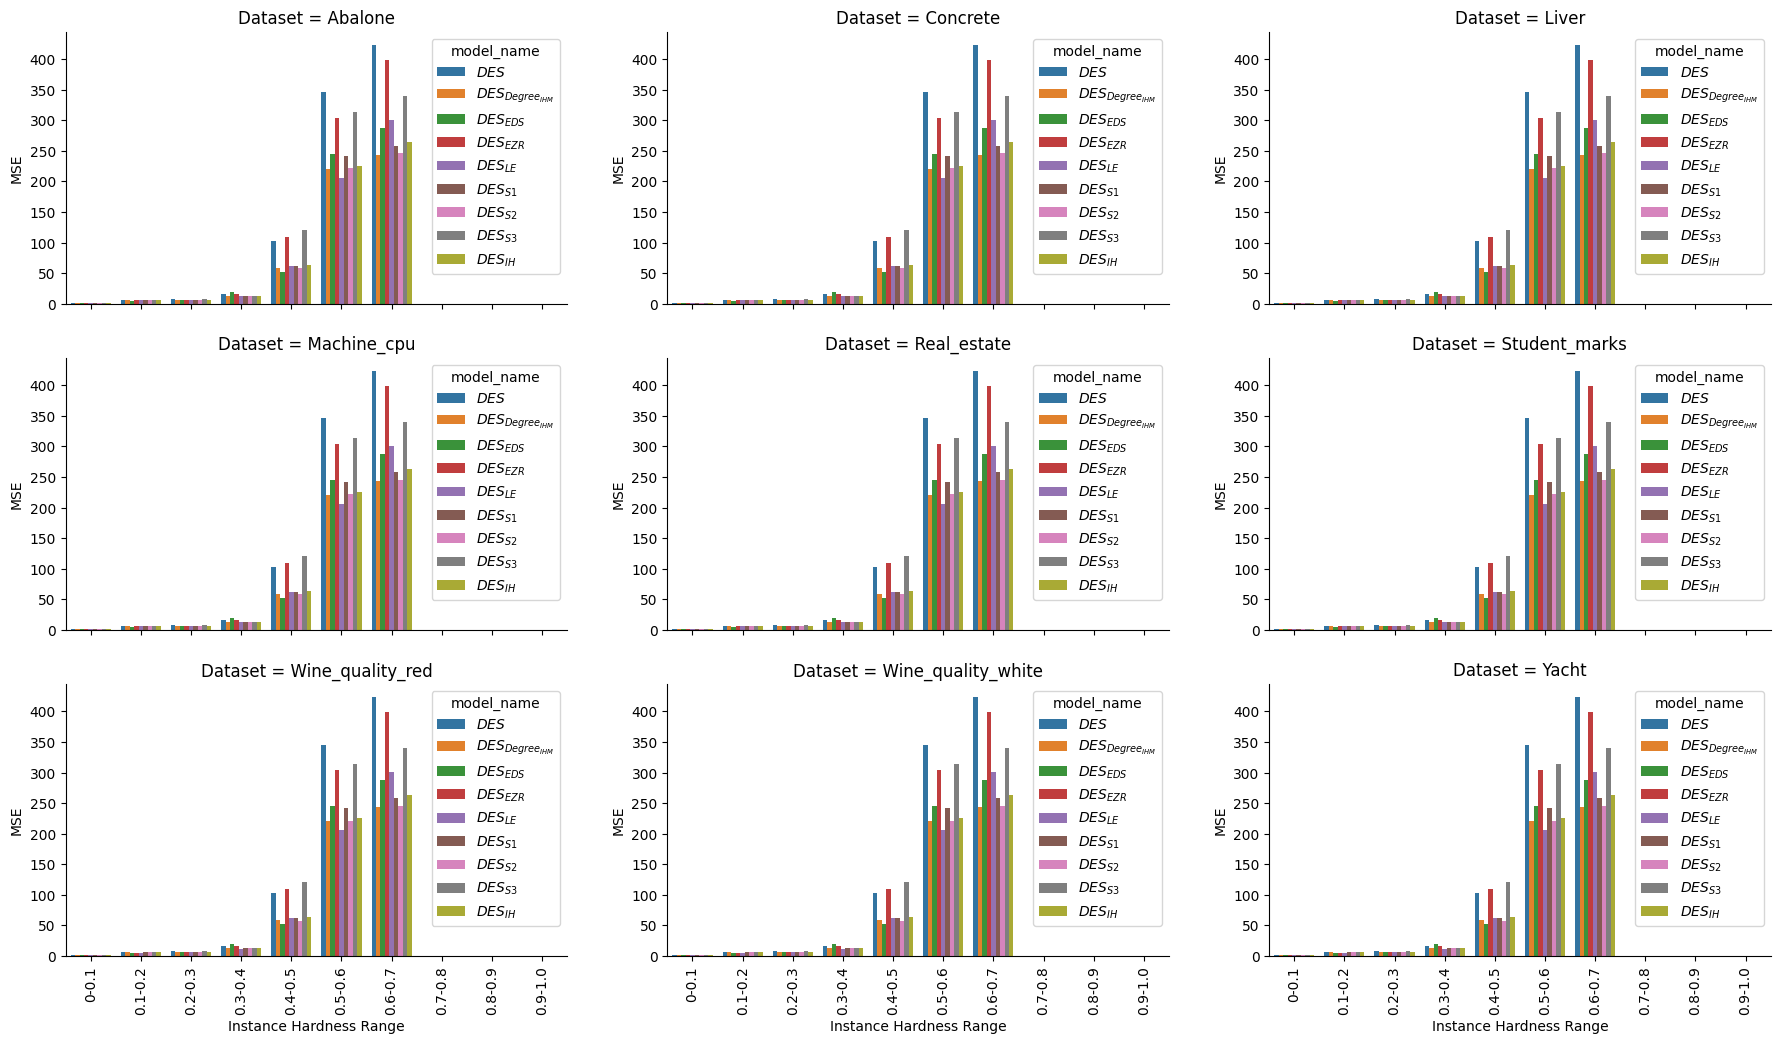

In [338]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(3, 3, figsize=(22, 12), sharex=True, sharey=False)
dataset_order = sorted(stats_per_ih['dataset_name'].unique())
df_plot = stats_per_ih\
    .query("dataset_name == @dataset and model_name != 'linear_reg'")\
    .replace(ensemble_latex_names)
for ax, dataset in zip(axes.flatten(), dataset_order):
    sns.barplot(
        ax=ax
        , data=df_plot
        , x='instance_hardness_bin'
        , y='avg_squared_error'
        , hue="model_name"
        # , fliersize=0.3
        , width=0.8
        , order = sorted(stats_per_ih['instance_hardness_bin'].unique())
        # , palette=sns.color_palette(['lightgrey'])
    )
    ax.set_title(f'Dataset = {dataset.capitalize()}')
    ax.set_xlabel('Instance Hardness Range')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylabel('MSE')

# plt.subplots_adjust(left=0.1,
#                     bottom=0.1, 
#                     right=0.8, 
#                     top=0.9, 
#                     wspace=0.5, 
#                     hspace=0.4)
sns.despine()
fig.savefig(
    fname='img/mse-all-dataset-combined.png'
    , dpi=300
    , format='png'
    , bbox_inches='tight'
)

In [238]:
# grid = sns.FacetGrid(
#     data=stats_per_ih.query("model_name != 'linear_reg'"),
#     col="dataset_name",
#     col_wrap=3,
#     hue="model_name",
#     height=4,
#     aspect=1.5,
#     sharey=False
# )
# grid.map(sns.barplot, "instance_hardness_bin", "avg_squared_error", alpha=0.4)
# grid.add_legend()


In [ ]:
all_dataset_all_data.groupby(["dataset_name", "model_name"]).agg(
    mse = ("avg_squared_error", "mean")
).query("model_name == 'baseline'")

,,mse
dataset_name,model_name,
abalone,baseline,66.851575
concrete,baseline,380.049531
liver,baseline,33.358693
machine_cpu,baseline,19915.84665
real_estate,baseline,322.370641
student_marks,baseline,4.09993
wine_quality_red,baseline,1.893199
wine_quality_white,baseline,3.476904
yacht,baseline,128.952362


In [237]:
all_dataset_all_data.query("model_name == 'baseline' and dataset_name == 'abalone'").shape

,mse,r2,mae,rmse,mape,execution_time,y_pred,y_true,status,model_name,partition,baseline_prediction,baseline_true,instance_hardness,V0,V1,V2,V3,V4,V5,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U,dataset_name,V6,V7,V8,V9,V10,instance_hardness_bin,squared_error
13770,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,8.112,7,success,baseline,1,8.112,7,0.171384,2.0,0.495,0.380,0.120,0.5730,0.2655,7.0,1.000000,0.999300,0.446360,0.944762,0.017801,0.145943,0.000,0.906392,0.339855,0,0.007373,0.563621,0.106201,0.500000,0.428571,abalone,0.1285,0.1440,NaN,NaN,NaN,0.1-0.2,1.236544
13771,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,5.381912,6,success,baseline,1,5.381912,6,0.130362,3.0,0.250,0.190,0.060,0.0765,0.0360,6.0,0.333333,0.999655,0.775144,0.888571,0.131113,0.298794,0.000,0.937994,0.061819,0,0.001754,0.703311,0.106201,0.500000,0.464286,abalone,0.0115,0.0245,NaN,NaN,NaN,0.1-0.2,0.382033
13772,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,4.191431,3,success,baseline,1,4.191431,3,0.201790,3.0,0.165,0.120,0.030,0.0215,0.0070,3.0,1.000000,0.999681,0.844349,0.888571,0.700155,0.758241,0.375,0.996409,0.340543,1,0.002512,0.713380,0.075007,0.500000,0.357143,abalone,0.0050,0.0050,NaN,NaN,NaN,0.2-0.3,1.419507
13773,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,10.785503,7,success,baseline,1,10.785503,7,0.342089,1.0,0.575,0.450,0.155,0.9480,0.4290,7.0,1.000000,0.999344,0.483238,0.000000,0.634882,0.145943,0.000,0.906392,0.523323,0,0.007648,0.777913,0.267927,1.000000,0.500000,abalone,0.2060,0.2590,NaN,NaN,NaN,0.3-0.4,14.33003
13774,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,12.648472,10,success,baseline,1,12.648472,10,0.261801,2.0,0.535,0.415,0.170,0.8790,0.2950,10.0,0.777778,0.999178,0.402538,0.633333,0.076006,0.038672,0.000,0.848216,0.418931,0,0.012120,0.731698,0.593966,1.000000,0.607143,abalone,0.1965,0.2850,NaN,NaN,NaN,0.2-0.3,7.014402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17942,4.735688,0.534709,1.488327,2.176164,0.146152,54.043138,10.070954,8,success,baseline,5,10.070954,8,0.158204,2.0,0.460,0.360,0.115,0.4755,0.2105,8.0,1.000000,0.999377,0.481082,0.846667,0.011351,0.038672,0.000,0.864017,0.235422,0,0.004342,0.587568,0.314336,0.500000,0.428571,abalone,0.1050,0.1600,NaN,NaN,NaN,0.1-0.2,4.288851
17943,4.735688,0.534709,1.488327,2.176164,0.146152,54.043138,10.307144,10,success,baseline,5,10.307144,10,0.154111,1.0,0.535,0.420,0.145,0.7910,0.3300,10.0,0.888889,0.999364,0.497845,0.889524,0.076006,0.038672,0.000,0.848216,0.191211,0,0.007894,0.682065,0.000000,1.000000,0.535714,abalone,0.1890,0.2500,NaN,NaN,NaN,0.1-0.2,0.094338
17944,4.735688,0.534709,1.488327,2.176164,0.146152,54.043138,8.470968,6,success,baseline,5,8.470968,6,0.192329,3.0,0.380,0.275,0.110,0.2560,0.1100,6.0,1.000000,0.999592,0.654454,0.860952,0.131113,0.298794,0.000,0.937994,0.305007,0,0.004766,0.615453,0.106201,0.666667,0.607143,abalone,0.0535,0.0755,NaN,NaN,NaN,0.1-0.2,6.105682
17945,4.735688,0.534709,1.488327,2.176164,0.146152,54.043138,8.272252,8,success,baseline,5,8.272252,8,0.144448,1.0,0.510,0.410,0.145,0.7960,0.3865,8.0,1.000000,0.999395,0.519397,0.000000,0.441224,0.038672,0.000,0.864017,0.267033,0,0.008614,0.710848,0.003114,0.666667,0.500000,abalone,0.1815,0.1955,NaN,NaN,NaN,0.1-0.2,0.074121


In [246]:
all_dataset_all_data.query("dataset_name == 'abalone'")

,mse,r2,mae,rmse,mape,execution_time,y_pred,y_true,status,model_name,partition,baseline_prediction,baseline_true,instance_hardness,V0,V1,V2,V3,V4,V5,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U,dataset_name,V6,V7,V8,V9,V10,instance_hardness_bin,squared_error
13770,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,8.112,7,success,baseline,1,8.112,7,0.171384,2.0,0.495,0.380,0.120,0.5730,0.2655,7.0,1.000000,0.999300,0.446360,0.944762,0.017801,0.145943,0.000,0.906392,0.339855,0,0.007373,0.563621,0.106201,0.500000,0.428571,abalone,0.1285,0.1440,NaN,NaN,NaN,0.1-0.2,1.236544
13771,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,5.381912,6,success,baseline,1,5.381912,6,0.130362,3.0,0.250,0.190,0.060,0.0765,0.0360,6.0,0.333333,0.999655,0.775144,0.888571,0.131113,0.298794,0.000,0.937994,0.061819,0,0.001754,0.703311,0.106201,0.500000,0.464286,abalone,0.0115,0.0245,NaN,NaN,NaN,0.1-0.2,0.382033
13772,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,4.191431,3,success,baseline,1,4.191431,3,0.201790,3.0,0.165,0.120,0.030,0.0215,0.0070,3.0,1.000000,0.999681,0.844349,0.888571,0.700155,0.758241,0.375,0.996409,0.340543,1,0.002512,0.713380,0.075007,0.500000,0.357143,abalone,0.0050,0.0050,NaN,NaN,NaN,0.2-0.3,1.419507
13773,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,10.785503,7,success,baseline,1,10.785503,7,0.342089,1.0,0.575,0.450,0.155,0.9480,0.4290,7.0,1.000000,0.999344,0.483238,0.000000,0.634882,0.145943,0.000,0.906392,0.523323,0,0.007648,0.777913,0.267927,1.000000,0.500000,abalone,0.2060,0.2590,NaN,NaN,NaN,0.3-0.4,14.33003
13774,4.929206,0.541049,1.533017,2.220181,0.150423,55.735508,12.648472,10,success,baseline,1,12.648472,10,0.261801,2.0,0.535,0.415,0.170,0.8790,0.2950,10.0,0.777778,0.999178,0.402538,0.633333,0.076006,0.038672,0.000,0.848216,0.418931,0,0.012120,0.731698,0.593966,1.000000,0.607143,abalone,0.1965,0.2850,NaN,NaN,NaN,0.2-0.3,7.014402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55535,4.746758,0.533621,1.580338,2.178705,0.158125,0.001278,8.957174,8,success,linear_reg,5,10.070954,8,0.158204,2.0,0.460,0.360,0.115,0.4755,0.2105,8.0,1.000000,0.999377,0.481082,0.846667,0.011351,0.038672,0.000,0.864017,0.235422,0,0.004342,0.587568,0.314336,0.500000,0.428571,abalone,0.1050,0.1600,NaN,NaN,NaN,0.1-0.2,0.916182
55536,4.746758,0.533621,1.580338,2.178705,0.158125,0.001278,10.739235,10,success,linear_reg,5,10.307144,10,0.154111,1.0,0.535,0.420,0.145,0.7910,0.3300,10.0,0.888889,0.999364,0.497845,0.889524,0.076006,0.038672,0.000,0.848216,0.191211,0,0.007894,0.682065,0.000000,1.000000,0.535714,abalone,0.1890,0.2500,NaN,NaN,NaN,0.1-0.2,0.546469
55537,4.746758,0.533621,1.580338,2.178705,0.158125,0.001278,7.367693,6,success,linear_reg,5,8.470968,6,0.192329,3.0,0.380,0.275,0.110,0.2560,0.1100,6.0,1.000000,0.999592,0.654454,0.860952,0.131113,0.298794,0.000,0.937994,0.305007,0,0.004766,0.615453,0.106201,0.666667,0.607143,abalone,0.0535,0.0755,NaN,NaN,NaN,0.1-0.2,1.870585
55538,4.746758,0.533621,1.580338,2.178705,0.158125,0.001278,9.15898,8,success,linear_reg,5,8.272252,8,0.144448,1.0,0.510,0.410,0.145,0.7960,0.3865,8.0,1.000000,0.999395,0.519397,0.000000,0.441224,0.038672,0.000,0.864017,0.267033,0,0.008614,0.710848,0.003114,0.666667,0.500000,abalone,0.1815,0.1955,NaN,NaN,NaN,0.1-0.2,1.343234


In [247]:
all_dataset_all_data.groupby(["dataset_name", "model_name"]).agg(
    avg_mse = ("mse", "mean"),
    avg_squared_error=("squared_error", "mean"),
    count = ("y_true", "count")
).query("model_name == 'baseline'")



,,avg_mse,avg_squared_error,count
dataset_name,model_name,,,
abalone,baseline,4.722726,4.722726,4177
concrete,baseline,47.446223,47.446223,1030
liver,baseline,12.369167,12.369167,345
machine_cpu,baseline,3405.395310,3405.39531,209
real_estate,baseline,45.315326,45.315326,415
student_marks,baseline,2.347651,2.347651,100
wine_quality_red,baseline,0.395167,0.395167,1599
wine_quality_white,baseline,0.458565,0.458565,4898
yacht,baseline,40.665587,40.665587,308


In [224]:
# grid = sns.FacetGrid(
#     data=all_dataset_all_data,
#     col="dataset_name",
#     col_wrap=3,
#     hue="model_name",
#     height=4,
#     aspect=1.5,
#     sharey=False
# )
# grid.map(sns.barplot, "instance_hardness", "squared_error", alpha=0.5)
# grid.add_legend()


In [24]:

# Save results
timestamp = dt.datetime.now().strftime('%Y%m%d_%H%M%S')
all_results.to_csv(f'detailed_results_{timestamp}.csv', index=False)

## Graveyard

In [68]:
# # Run experiments for all datasets
# for dataset in partitions_dict.keys():
#     try:
#         results = run_experiment(dataset)
#     except Exception as e:
#         print(f"Error processing {dataset}: {str(e)}")

In [69]:
# # Calculate summary statistics
# summary = results.groupby(['dataset', 'method']).agg({
#     'mse': ['mean', 'std'],
#     'r2': ['mean', 'std'],
#     'mae': ['mean', 'std'],
#     'rmse': ['mean', 'std'],
#     'mape': ['mean', 'std']
# }).round(4)

# # Save results
# timestamp = dt.datetime.now().strftime('%Y%m%d_%H%M%S')
# # results.to_csv(f'detailed_results_{timestamp}.csv', index=False)
# # summary.to_csv(f'summary_results_{timestamp}.csv')

In [20]:
# results = pd.read_csv("detailed_results_20250413_012125.csv")
# summary = results.groupby(['Dataset', 'Method']).agg({
#     'MSE': ['mean', 'std'],
#     'R2': ['mean', 'std'],
#     'MAE': ['mean', 'std'],
#     'RMSE': ['mean', 'std'],
#     'MAPE': ['mean', 'std']
# }).round(4)
# # Print summary table
# print("\n=== Summary Results ===")
# display(summary)


=== Summary Results ===


MSE              R2             MAE          \
                           mean     std    mean     std    mean     std   
Dataset          Method                                                   
wine_quality_red DES     0.4663  0.0298  0.2842  0.0512  0.4690  0.0176   
                 DES_IH  0.6401  0.0780  0.0165  0.1324  0.5022  0.0194   
                 Linear  0.4234  0.0282  0.3498  0.0504  0.5037  0.0241   

                           RMSE            MAPE          
                           mean     std    mean     std  
Dataset          Method                                  
wine_quality_red DES     0.6826  0.0220  0.0866  0.0030  
                 DES_IH  0.7989  0.0485  0.0921  0.0037  
                 Linear  0.6504  0.0219  0.0923  0.0043